# Proyecto Integrador M4 - Machine Learning

## Avance 1: Regresión Logística y Funadamentos

### Predección de fuga de clientes en FinanceGuard

**Estudiante:** Joaquín Domingo  
**Rol:** Científico de Datos Junior

#### Contexto del Proyecto
FinanceGuard es un banco digital que ha experimentado un crecimiento exponencial en los últimos años, alcanzando 10.000 clientes activos. Sin embargo, la dirección ha detectado un incremento preocupante en la tasa de abandono de clientes (churn), que actualmente alcanza el 20% anual, resultando en pérdidas millonarias.  


#### Rol del estudiante
Siendo un Cientifico de Datos Junior, el objetivo es desarrollar un modelo de Machine Learning completo que prediga qué clientes tienen mayor probabilidad de abandonar el banco. Este modelo permitirá al equipo de retención implementar estrategías personalizadas para retener a los clientes en riesgo, con el fin de reducir el churn al 15%.

#### Comprensión del Problema
El objetivo del proyecto es desarrollar un modelo de Machine Learning que permita identificar qué clientes presentan una mayor probabilidad de abandonar el banco. Esta información podrá ser utilizada por el equipo de retención para diseñar estrategias personalizadas y orientar acciones hacia los clientes con mayor riesgo.

En este primer avance se utilizará una Regresión Logística como modelo baseline. Este modelo servirá como punto de referencia para comparar, más adelante, algoritmos de mayor complejidad.

La variable objetivo es `Exited`, donde:

- `0`: el cliente permaneció en el banco.
- `1`: el cliente abandonó el banco.

#### 1. Librerías

In [1]:
#Analisis
import numpy as np
import pandas as pd

#Gráficos
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

sns.set_theme(style="whitegrid")

#Conf xa visualiizar mejor las tablas
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

print("Librerias Importadas Correctamente.")


Librerias Importadas Correctamente.


#### 2. Carga de Dataset

In [2]:
# Ruta del archivo
ruta_dataset = Path("Churn_Modelling.csv")

# Verificación de existencia
if not ruta_dataset.exists():
    raise FileNotFoundError(
        "No se encontró el archivo 'Churn_Modelling.csv'. "
        "Verificá que se encuentre en la misma carpeta que el notebook."
    )

# Carga del dataset
df = pd.read_csv(ruta_dataset)

print("Dataset cargado correctamente.")
print(f"Cantidad de filas: {df.shape[0]:,}")
print(f"Cantidad de columnas: {df.shape[1]}")

Dataset cargado correctamente.
Cantidad de filas: 10,000
Cantidad de columnas: 14


In [3]:
df.head

<bound method NDFrame.head of       RowNumber  CustomerId    Surname  CreditScore Geography  Gender  Age  \
0             1    15634602   Hargrave          619    France  Female   42   
1             2    15647311       Hill          608     Spain  Female   41   
2             3    15619304       Onio          502    France  Female   42   
3             4    15701354       Boni          699    France  Female   39   
4             5    15737888   Mitchell          850     Spain  Female   43   
...         ...         ...        ...          ...       ...     ...  ...   
9995       9996    15606229   Obijiaku          771    France    Male   39   
9996       9997    15569892  Johnstone          516    France    Male   35   
9997       9998    15584532        Liu          709    France  Female   36   
9998       9999    15682355  Sabbatini          772   Germany    Male   42   
9999      10000    15628319     Walker          792    France  Female   28   

      Tenure    Balance  NumOfPro

In [4]:
print(f"Dimensiones del dataset: {df.shape}")

print("\nColumnas disponibles:")

for numero, columna in enumerate(df.columns, start=1):
    print(f"{numero}. {columna}")

Dimensiones del dataset: (10000, 14)

Columnas disponibles:
1. RowNumber
2. CustomerId
3. Surname
4. CreditScore
5. Geography
6. Gender
7. Age
8. Tenure
9. Balance
10. NumOfProducts
11. HasCrCard
12. IsActiveMember
13. EstimatedSalary
14. Exited


In [5]:
# Que tipo de datos tengo
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


El dataset contiene 10.000 registros y 14 variables. La observación inicial a través de `df.info()` muestra que todas las columnas poseen información completa, ya que cada una contiene 10.000 valores no nulos.

Se identificaron variables numéricas, categóricas y binarias. Las columnas `RowNumber` y `CustomerId` funcionan como identificadores y no representan características propias del comportamiento de los clientes, por lo que posteriormente se evaluará su exclusión del modelo.
  
Las variables de formato texto son categóricas. Estas son: 
- `Surname`: indica el apellido del cliente.

- `Geography`: indica el país del cliente. Estos pueden ser Alemania, España y Francia.

- `Gender`: es el género del cliente (masculino o femenino)


In [6]:
#De las variables numéricas - Estadistica descriptiva
df.describe().T

,count,mean,std,min,25%,50%,75%,max
RowNumber,"10,000.00","5,000.50","2,886.90",1.00,"2,500.75","5,000.50","7,500.25","10,000.00"
CustomerId,"10,000.00","15,690,940.57","71,936.19","15,565,701.00","15,628,528.25","15,690,738.00","15,753,233.75","15,815,690.00"
CreditScore,"10,000.00",650.53,96.65,350.00,584.00,652.00,718.00,850.00
Age,"10,000.00",38.92,10.49,18.00,32.00,37.00,44.00,92.00
Tenure,"10,000.00",5.01,2.89,0.00,3.00,5.00,7.00,10.00
Balance,"10,000.00","76,485.89","62,397.41",0.00,0.00,"97,198.54","127,644.24","250,898.09"
NumOfProducts,"10,000.00",1.53,0.58,1.00,1.00,1.00,2.00,4.00
HasCrCard,"10,000.00",0.71,0.46,0.00,0.00,1.00,1.00,1.00
IsActiveMember,"10,000.00",0.52,0.50,0.00,0.00,1.00,1.00,1.00
EstimatedSalary,"10,000.00","100,090.24","57,510.49",11.58,"51,002.11","100,193.91","149,388.25","199,992.48"


En esta tabla, sólo se pueden observar las estadísticas de las variables numéricas.
- `RowNumber`: indica el índice de la fila.  Marca que el mínimo es 1 y el máximo 10.000. Esta variable se comporta como un número consecutivo, lo que no representa una característica real del cliente. Por lo tanto, es probable que se excluya antes de entrenar el modelo.

- `CustomerID`: es el identificador único de cada cliente.  Pandas lo identifica como variable numérica pero no es una variable cuantitativa. Esta variable se excluirá del modelo.

- `CreditScore`: es la puntuación crediticia del cliente. Por lo que se ve a simple vista, la media y la mediana son muy similares, lo que puede sugerir una distribución equilibrada.

- `Age`: es la edad del cliente. El valor mínimo es 18 lo que indica que todos son mayores de edad, pero el valor máximo es 92 lo que puede llegar a ser un valor atípico (un valor atípico no implica que este mal). Esto se verá maás adelante cuando se analicen las variables.

- `Tenure`: indica el número de años que el cliente ha estado en el banco. El rango parece coherente, siendo el mínimo 0 años, el máximo 10 años y el promedio es de 5,01 años.

- `Balance`: indica el saldo de cuenta del cliente. Que el 25% sea igual a 0 implica que una cuarta parte de los registros tiene saldo cero en su cuenta. No implica que sea un error. Pero si hay que analizar la distribucion, ya que puede existir una gran concentración de registros en cero.

- `NumOfProducts`: es el número de productos que ha comprado el cliente. La mayoria de los clientes tiene 1 producto, donde vemos que los que más tienen llegan a 4 productos.

- `HasCrCard`: indica si el cliente tiene o no tarjeta de crédito (si es 1 implica que sí, y si es 0 implica que no). La media es de 0,71, lo que sugiere que el 71% de los clientes tienen tarjeta de crédito.

- `IsActiveMember`: implica si el cliente es miembro activo (Si=1) o no (No=0). La media en esta variable es de 0,52, lo que sugiere que tiene una distribución relativamente equilibrada entre miembros activos y no.

- `EstimatedSalary`: implica el salario anual estimado del cliente.  En este caso, la media y la mediana son casi iguales. Además el valor mínimo es muy bajo, pero no se puede definir nada hasta no realizar un análisis.

- `Exited`: implica si el cliente dejó el banco (Si=1; No=0) o no. Ésta es la variable objetivo del proyecto. En esta variable, la media es de 0,20 lo que implica que alrededor del 20% de los clientes abandonaron el banco.  Si vemos esto, podemos ver que esto es el problema principal que está atravesando FinanceGuard.

#### 3. Calidad de los Datos

##### Evaluación formal de la calidad de los datos

Antes de realizar el análisis exploratorio y entrenar el modelo, se evaluará la calidad del dataset. Esta etapa permite identificar problemas que podrían afectar la confiabilidad del análisis o el aprendizaje del algoritmo.

Se verificarán los siguientes aspectos:

- Presencia de valores faltantes
- Existencia de cadenas de texto vacías
- Registros duplicados
- Unicidad de los identificadores
- Cantidad de valores únicos por variable
- Consistencia de las variables categóricas
- Validez de las variables binarias
- Presencia de valores fuera de rangos lógicamente esperados
- Distribución inicial de la variable objetivo

##### 3.1 Valores Faltantes

In [7]:
# Cantidad y porcentaje de valores faltantes por variable
calidad_nulos = pd.DataFrame({
    "Valores faltantes": df.isna().sum(),
    "Porcentaje (%)": (df.isna().mean() * 100).round(2)
})

calidad_nulos

,Valores faltantes,Porcentaje (%)
RowNumber,0,0.00
CustomerId,0,0.00
Surname,0,0.00
CreditScore,0,0.00
Geography,0,0.00
Gender,0,0.00
Age,0,0.00
Tenure,0,0.00
Balance,0,0.00
NumOfProducts,0,0.00


In [8]:
# Cantidad total de valores faltantes

total_nulos = df.isna().sum().sum()

print(f"Cantidad total de valores faltantes: {total_nulos}")

Cantidad total de valores faltantes: 0


Luego de este análisis se determina que el dataset no tiene valores faltantes detectados. Pero igualmente se debe revisar que las columnas de texto no tengan cadenas vacías, ya que una celda con espacios o con "" se puede conciderar como un valor nulo,

##### 3.2 Cadenas vacías en variables de texto

In [9]:
# Identificación de las variables de texto

columnas_texto = df.select_dtypes(include="object").columns

# Búsqueda de cadenas vacías o compuestas únicamente por espacios

cadenas_vacias = pd.DataFrame({
    "Variable": columnas_texto,
    "Cadenas vacías": [
        df[columna].str.strip().eq("").sum()
        for columna in columnas_texto
    ]
})

cadenas_vacias

,Variable,Cadenas vacías
0,Surname,0
1,Geography,0
2,Gender,0


Al revisar estas variable categóricas, se observa que no tienen datos faltantes o cadenas vacías.

##### 3.3 Registros Duplicados

In [10]:
# Identificación de registros completamente duplicados
filas_duplicadas = df.duplicated().sum()

print(f"Cantidad de filas completamente duplicadas: {filas_duplicadas}")

Cantidad de filas completamente duplicadas: 0


In [11]:
# Verificación de duplicados en las columnas identificadoras
duplicados_identificadores = pd.DataFrame({
    "Variable": ["RowNumber", "CustomerId"],
    "Valores únicos": [
        df["RowNumber"].nunique(),
        df["CustomerId"].nunique()
    ],
    "Valores duplicados": [
        df["RowNumber"].duplicated().sum(),
        df["CustomerId"].duplicated().sum()
    ]
})

duplicados_identificadores

,Variable,Valores únicos,Valores duplicados
0,RowNumber,10000,0
1,CustomerId,10000,0


Se puede determinar que no existen filas completamente duplicadas. Por lo cual, cada valor de `RowNumber` es único, al igual que cada valor de `CustomerId`. Esto significa que cada registro corresponde a un cliente diferente.

##### 3.4 Cardinalidad de las Variables

In [12]:
# Cantidad y porcentaje de valores únicos por variable
cardinalidad = pd.DataFrame({
    "Variable": df.columns,
    "Valores únicos": df.nunique().values,
    "Porcentaje de unicidad (%)": (
        df.nunique().values / len(df) * 100
    ).round(2)
})
cardinalidad

,Variable,Valores únicos,Porcentaje de unicidad (%)
0,RowNumber,10000,100.00
1,CustomerId,10000,100.00
2,Surname,2932,29.32
3,CreditScore,460,4.60
4,Geography,3,0.03
5,Gender,2,0.02
6,Age,70,0.70
7,Tenure,11,0.11
8,Balance,6382,63.82
9,NumOfProducts,4,0.04


Esta revisión permite ver diferentes tipos de variables:
* `RowNumber` y `CustomerId`: funcionan como indicadores y tienen diferentes valores para cada cliente.
* `Surname`: tiene una cardinalidad eleveda con un total de 2932 apellidos diferentes.
* `Geography`y `Gender`: son variables categóricas y de baja cardinalidad.
* `HasCrCard`, IsActiveMember`y Èxited`: tienen dos valores posibles. Las tres variables son variables binarias.


##### 3.5 Consistencia de las Variables Categóricas

In [13]:
# Categorías presentes en las variables categóricas predictoras
for columna in ["Geography", "Gender"]:
    print(f"{columna}:")
    print(sorted(df[columna].unique()))
    print()

Geography:
['France', 'Germany', 'Spain']

Gender:
['Female', 'Male']



In [14]:
# Verificación de espacios al inicio o al final de las variables de texto
espacios_innecesarios = pd.DataFrame({
    "Variable": columnas_texto,
    "Registros con espacios adicionales": [
        (
            df[columna]
            != df[columna].str.strip()
        ).sum()
        for columna in columnas_texto
    ]
})

espacios_innecesarios

,Variable,Registros con espacios adicionales
0,Surname,0
1,Geography,0
2,Gender,0


Con esta revisión, no se detectaron cadenas vacías ni espacios adicionales al inicio o final de los valores.

##### 3.6 Validación de las Variables Binarias

In [15]:
# Validación de las variables binarias
variables_binarias = [
    "HasCrCard",
    "IsActiveMember",
    "Exited"
]

valores_permitidos = {0, 1}

resultados_binarios = []

for columna in variables_binarias:

    valores_observados = set(
        df[columna].dropna().unique()
    )

    valores_invalidos = (
        valores_observados - valores_permitidos
    )

    resultados_binarios.append({
        "Variable": columna,
        "Valores observados": sorted(valores_observados),
        "Valores inválidos": sorted(valores_invalidos),
        "Estado": (
            "Válida"
            if len(valores_invalidos) == 0
            else "Revisar"
        )
    })

validacion_binarias = pd.DataFrame(
    resultados_binarios
)

validacion_binarias

,Variable,Valores observados,Valores inválidos,Estado
0,HasCrCard,"[0, 1]",[],Válida
1,IsActiveMember,"[0, 1]",[],Válida
2,Exited,"[0, 1]",[],Válida


Las tres variables analizadas (`HasCrCard`, `IsActiveMember`y `Exited`) son binarias y deberían contener unicamentes valores 0 y 1. Al hacer la revisión se observan que están codificadas correctamente.

##### 3.7 Checkeo de Rangos Numéricos

In [16]:
# Valores mínimos y máximos observados
variables_numericas_analisis = [
    "CreditScore",
    "Age",
    "Tenure",
    "Balance",
    "NumOfProducts",
    "EstimatedSalary"
]

rangos_numericos = (
    df[variables_numericas_analisis]
    .agg(["min", "max"])
    .T
    .rename(
        columns={
            "min": "Valor mínimo",
            "max": "Valor máximo"
        }
    )
)

rangos_numericos

,Valor mínimo,Valor máximo
CreditScore,350.00,850.00
Age,18.00,92.00
Tenure,0.00,10.00
Balance,0.00,"250,898.09"
NumOfProducts,1.00,4.00
EstimatedSalary,11.58,"199,992.48"


De acuerdo a la definición que se hizo en el Punto 2 de este análisis, los valores parecen lógicamente posibles.

##### 3.8 Checkeo de Valores lógicamente Inválidos

In [17]:
# Reglas básicas de consistencia lógica
reglas_calidad = {
    "CreditScore menor que cero":
        (df["CreditScore"] < 0).sum(),

    "Edad menor que 18 años":
        (df["Age"] < 18).sum(),

    "Antigüedad negativa":
        (df["Tenure"] < 0).sum(),

    "Saldo negativo":
        (df["Balance"] < 0).sum(),

    "Cantidad de productos menor que 1":
        (df["NumOfProducts"] < 1).sum(),

    "Salario estimado negativo":
        (df["EstimatedSalary"] < 0).sum()
}

validacion_logica = pd.DataFrame(
    reglas_calidad.items(),
    columns=[
        "Regla evaluada",
        "Cantidad de registros inválidos"
    ]
)

validacion_logica

,Regla evaluada,Cantidad de registros inválidos
0,CreditScore menor que cero,0
1,Edad menor que 18 años,0
2,Antigüedad negativa,0
3,Saldo negativo,0
4,Cantidad de productos menor que 1,0
5,Salario estimado negativo,0


Como se puede observar en la tabla de arriba, todos los valores son correctos, no hay registros inválidos en el dataset.

##### 3.9 Análisis de Saldos iguales a Cero

In [18]:
# Cantidad y porcentaje de clientes con saldo igual a cero
cantidad_saldo_cero = (
    df["Balance"] == 0
).sum()

porcentaje_saldo_cero = (
    df["Balance"]
    .eq(0)
    .mean()
    * 100
)

print(
    f"Clientes con saldo igual a cero: "
    f"{cantidad_saldo_cero:,}"
)

print(
    f"Porcentaje sobre el total: "
    f"{porcentaje_saldo_cero:.2f}%"
)

Clientes con saldo igual a cero: 3,617
Porcentaje sobre el total: 36.17%


Revisando los **saldos iguales a cero** se observan un hallazgo importante, el 36.17% de los clientes tienen un saldo de cero en sus cuentas. Pero que el valor sea cero no implica que haya un faltante de dato ni que sea un error.  
Esto representa que hay 3617 clientes que actualmente no cuentan con fondos depositados en sus cuentas. Por lo tanto, no se reemplazaran estos valores ni se eliminarán del registro.

##### 3.10 Validación de la Variable Objetivo

In [19]:
# Distribución absoluta y porcentual de la variable objetivo
distribucion_objetivo = pd.DataFrame({
    "Cantidad": (
        df["Exited"]
        .value_counts()
        .sort_index()
    ),

    "Porcentaje (%)": (
        df["Exited"]
        .value_counts(
            normalize=True
        )
        .sort_index()
        .mul(100)
        .round(2)
    )
})

distribucion_objetivo.index = [
    "Permaneció (0)",
    "Abandonó (1)"
]

distribucion_objetivo

,Cantidad,Porcentaje (%)
Permaneció (0),7963,79.63
Abandonó (1),2037,20.37


Esta revisión confirma el problema que se detectó previamente, que existe un 20.37% de abandono de los clientes. Un porcentaje demasiado elevado.

**Conclusión de la Evaluación de la Calidad de los Datos**

La evaluación formal indica que el dataset presenta una calidad adecuada para continuar con el análisis exploratorio y el modelado.

Principales resultados:

- No se detectaron valores faltantes.
- No existen cadenas de texto vacías.
- No se identificaron registros duplicados.
- `RowNumber` y `CustomerId` poseen valores únicos para los 10.000 registros.
- Las variables categóricas presentan categorías consistentes y no contienen espacios adicionales.
- Las variables binarias contienen exclusivamente los valores 0 y 1.
- No se encontraron edades, antigüedades, saldos, cantidades de productos ni salarios con valores lógicamente inválidos.
- Se identificaron 3.617 clientes con saldo igual a cero, equivalentes al 36,17% del dataset. Estos valores se consideran observaciones válidas y no datos faltantes.
- La variable objetivo presenta 7.963 clientes que permanecieron y 2.037 que abandonaron el banco, correspondientes al 79,63% y 20,37%, respectivamente.

En consecuencia, no será necesario eliminar registros, corregir categorías ni aplicar técnicas de imputación. El desbalance observado en la variable objetivo no constituye un problema de calidad, pero se deberá considerar durante la evaluación del modelo.

#### 4. Análisis Exploratorio de Datos (EDA)

Este análisis permite comprender la distribución de las variables, identificar patrones y estudiar las posibles relaciones entre las características de los clientes y la variable objetivo (`Exited`).

##### 4.1 Distribución de la Variable Objetivo

In [20]:
# Distribución absoluta y porcentaje de la variable objetivo 'Exited'
distribucion_exited = (
    df["Exited"]
    .value_counts()
    .sort_index()
    .rename_axis("Exited")
    .reset_index(name="Cantidad")
)

distribucion_exited["Porcentaje (%)"] = (
    distribucion_exited["Cantidad"]
    / len(df)
    * 100
).round(2)

distribucion_exited["Clase"] = distribucion_exited["Exited"].map({
    0: "Permaneció",
    1: "Abandonó"
})

distribucion_exited[
    ["Exited", "Clase", "Cantidad", "Porcentaje (%)"]
]

,Exited,Clase,Cantidad,Porcentaje (%)
0,0,Permaneció,7963,79.63
1,1,Abandonó,2037,20.37


([<matplotlib.axis.XTick at 0x24ad259e660>,
 [Text(0, 0, 'Permaneció (0)'), Text(1, 0, 'Abandonó (1)')])

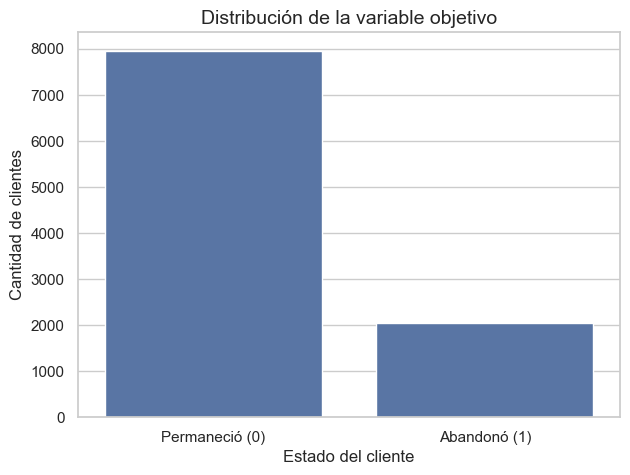

In [21]:
# Distribución visual de la variable objetivo
plt.figure(figsize=(7, 5))

ax = sns.countplot(
    data=df,
    x="Exited"
)

plt.title(
    "Distribución de la variable objetivo",
    fontsize=14
)

plt.xlabel(
    "Estado del cliente"
)

plt.ylabel(
    "Cantidad de clientes"
)

plt.xticks(
    ticks=[0, 1],
    labels=[
        "Permaneció (0)",
        "Abandonó (1)"
    ]
)

La variable objetivo `Exited`tiene una distribución desbalanceada:
* El 79.63% de los clientes permaneció en el banco
* El 20.37% de los clientes abandonó el banco

El desbalance que se observa no es extremo pero se tendrá que considerar durante la división de los datos y evaluación del modelo.

Es por ello que la Regresión Logística no se analizará únicamente con accuracy, sino también se utilizarán precision, recall, F1-score, matriz de confusion y ROC-AUC. 

'##### 4. Función Auxiliar para Analizar Churn
Con esta función nos permite calcular cantidad de clientes, cantidad de abandonos y porcentaje de churn evitando repetir el mismo código para cada una de las variables categoricas.

In [22]:
def resumen_churn_por_categoria(
    data,
    variable
):

    """
    Calcula la cantidad de clientes,
    la cantidad de abandonos y la tasa
    de churn para cada categoría.
    """

    resumen = (
        data
        .groupby(variable)["Exited"]
        .agg(
            Cantidad_clientes="count",
            Clientes_que_abandonaron="sum",
            Tasa_de_churn="mean"
        )
        .reset_index()
    )

    resumen["Tasa_de_churn (%)"] = (
        resumen["Tasa_de_churn"]
        * 100
    ).round(2)

    return resumen.drop(
        columns="Tasa_de_churn"
    )

##### 4.2 Variables Demográficas

###### 4.2.1 Género

In [23]:
# Distribución y % de churn según género
churn_genero = (
    resumen_churn_por_categoria(
        df,
        "Gender"
    )
)

churn_genero

,Gender,Cantidad_clientes,Clientes_que_abandonaron,Tasa_de_churn (%)
0,Female,4543,1139,25.07
1,Male,5457,898,16.46


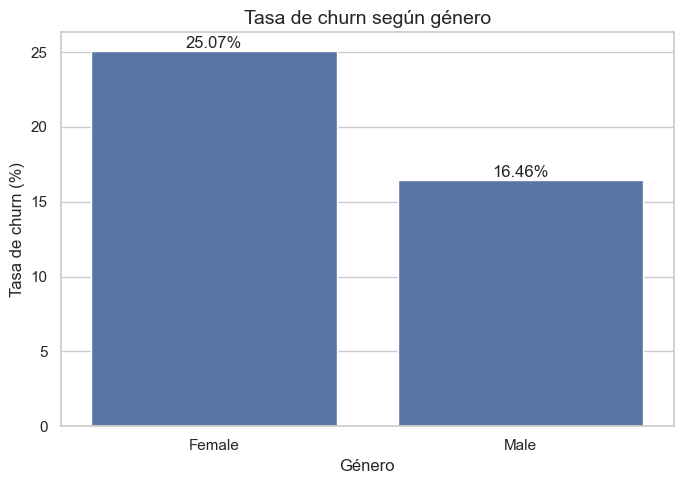

In [24]:
# Tasa de churn según género
plt.figure(figsize=(7, 5))

ax = sns.barplot(
    data=churn_genero,
    x="Gender",
    y="Tasa_de_churn (%)"
)

plt.title(
    "Tasa de churn según género",
    fontsize=14
)

plt.xlabel(
    "Género"
)

plt.ylabel(
    "Tasa de churn (%)"
)

for barra in ax.patches:

    valor = barra.get_height()

    ax.annotate(
        f"{valor:.2f}%",
        (
            barra.get_x()
            + barra.get_width() / 2,
            valor
        ),
        ha="center",
        va="bottom"
    )

plt.tight_layout()

plt.show()

Se puede observar que las clientas registran una tasa de abandono aproximada del 25,07%, mientras que los clientes presentan una tasa cercana al 16,46%.

Se observa una diferencia descriptiva entre ambos grupos. Sin embargo, este análisis no permite afirmar que el género sea la causa del abandono. La relación deberá evaluarse posteriormente en conjunto con las demás variables mediante la Regresión Logística.

###### 4.2.2 Ubicación Geográfica

In [25]:
# Distribución y tasa de churn según país
churn_geografia = (
    resumen_churn_por_categoria(
        df,
        "Geography"
    )
)

churn_geografia

,Geography,Cantidad_clientes,Clientes_que_abandonaron,Tasa_de_churn (%)
0,France,5014,810,16.15
1,Germany,2509,814,32.44
2,Spain,2477,413,16.67


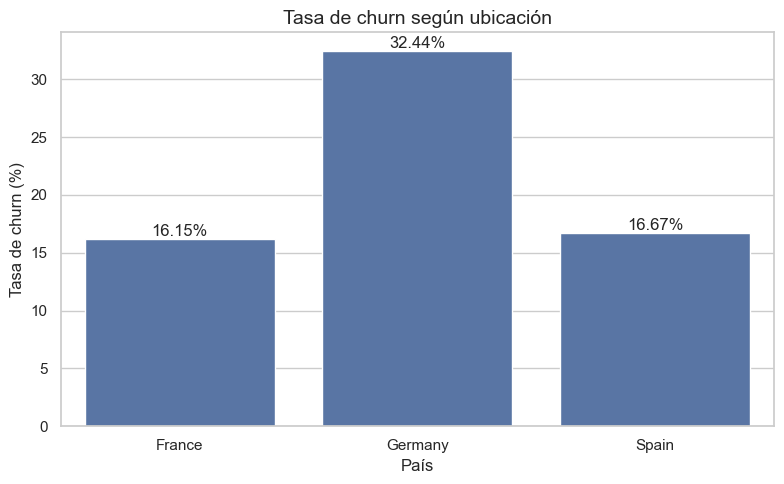

In [26]:
# Tasa de churn según ubicación
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=churn_geografia,
    x="Geography",
    y="Tasa_de_churn (%)"
)

plt.title(
    "Tasa de churn según ubicación",
    fontsize=14
)

plt.xlabel(
    "País"
)

plt.ylabel(
    "Tasa de churn (%)"
)

for barra in ax.patches:

    valor = barra.get_height()

    ax.annotate(
        f"{valor:.2f}%",
        (
            barra.get_x()
            + barra.get_width() / 2,
            valor
        ),
        ha="center",
        va="bottom"
    )

plt.tight_layout()

plt.show()

Se observa que Alemania presenta la mayor tasa de abandono con un 32.44%. Lo siguen España y Francia con tasas del 16.67% y 16.15% respectivamente.

La ubicación geográfica podría estar asociada con diferencias relevantes en el comportamiento de abandono. Cuando se realice la Regresión Logística, permitirá evaluar si esta relación se mantiene al considerar el resto de variables simultaneamente.


###### 4.2.3 Edad

In [27]:
# Estadísticas de edad según la variable objetivo
resumen_edad = (
    df
    .groupby("Exited")["Age"]
    .agg([
        "count",
        "mean",
        "median",
        "std",
        "min",
        "max"
    ])
    .round(2)
)

resumen_edad

,count,mean,median,std,min,max
Exited,,,,,,
0,7963,37.41,36.00,10.13,18,92
1,2037,44.84,45.00,9.76,18,84


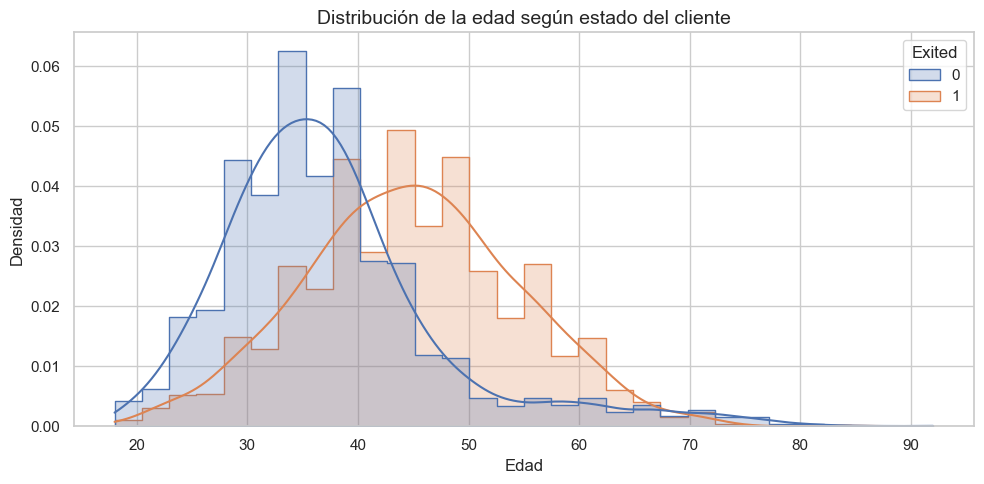

In [28]:
# Distribución de la edad según abandono
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Age",
    hue="Exited",
    bins=30,
    kde=True,
    stat="density",
    common_norm=False,
    element="step"
)

plt.title(
    "Distribución de la edad según estado del cliente",
    fontsize=14
)

plt.xlabel(
    "Edad"
)

plt.ylabel(
    "Densidad"
)

plt.tight_layout()

plt.show()

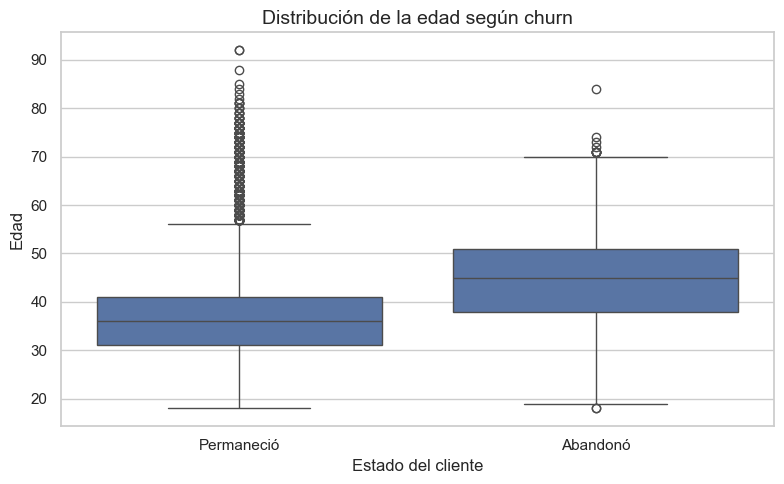

In [29]:
# Edad según estado del cliente
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Exited",
    y="Age"
)

plt.title(
    "Distribución de la edad según churn",
    fontsize=14
)

plt.xlabel(
    "Estado del cliente"
)

plt.ylabel(
    "Edad"
)

plt.xticks(
    ticks=[0, 1],
    labels=[
        "Permaneció",
        "Abandonó"
    ]
)

plt.tight_layout()

plt.show()

**Edad según Churn**

Los clientes que abandonaron el banco presentan una edad promedio aproximada de 44,84 años, mientras que quienes permanecieron tienen una edad promedio cercana a 37,41 años.

La diferencia también se observa en las medianas: 45 años para los clientes que abandonaron y 36 años para quienes permanecieron.

La edad muestra una asociación descriptiva relevante con el abandono. Esto podría constituir una variable importante para el modelo.

###### 4.2.4 Antigüedad

In [30]:
# Tasa de churn según antigüedad
churn_tenure = (
    resumen_churn_por_categoria(
        df,
        "Tenure"
    )
)

churn_tenure

,Tenure,Cantidad_clientes,Clientes_que_abandonaron,Tasa_de_churn (%)
0,0,413,95,23.00
1,1,1035,232,22.42
2,2,1048,201,19.18
3,3,1009,213,21.11
4,4,989,203,20.53
5,5,1012,209,20.65
6,6,967,196,20.27
7,7,1028,177,17.22
8,8,1025,197,19.22
9,9,984,213,21.65


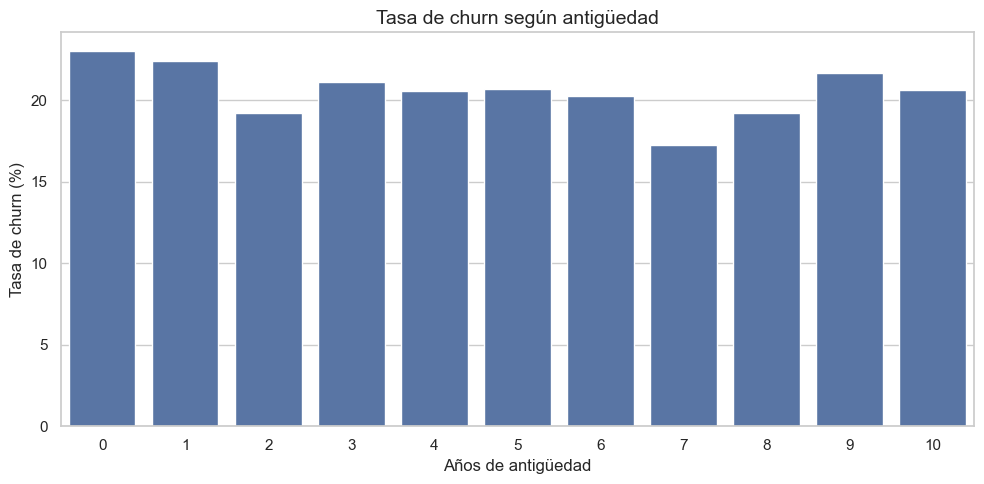

In [31]:
# Tasa de churn según antigüedad
plt.figure(figsize=(10, 5))

sns.barplot(
    data=churn_tenure,
    x="Tenure",
    y="Tasa_de_churn (%)"
)

plt.title(
    "Tasa de churn según antigüedad",
    fontsize=14
)

plt.xlabel(
    "Años de antigüedad"
)

plt.ylabel(
    "Tasa de churn (%)"
)

plt.tight_layout()

plt.show()

La tasa de churn presenta variaciones moderadas entre los diferentes niveles de antigüedad, pero no se observa un patrón creciente o decreciente definido.

La antigüedad podría aportar información al modelo, aunque su relación con el abandono no es tan marcada como con variables como la edad, género o ubicación.

##### 4.3 Variables Financieras

In [32]:
# Comparación de variables financieras según la variable Exited
variables_financieras = [
    "CreditScore",
    "Balance",
    "EstimatedSalary"
]

resumen_financiero = (
    df
    .groupby("Exited")[
        variables_financieras
    ]
    .agg([
        "mean",
        "median"
    ])
    .round(2)
)

resumen_financiero

CreditScore          Balance            EstimatedSalary           
              mean median      mean     median            mean     median
Exited                                                                   
0           651.85 653.00 72,745.30  92,072.68       99,738.39  99,645.04
1           645.35 646.00 91,108.54 109,349.29      101,465.68 102,460.84

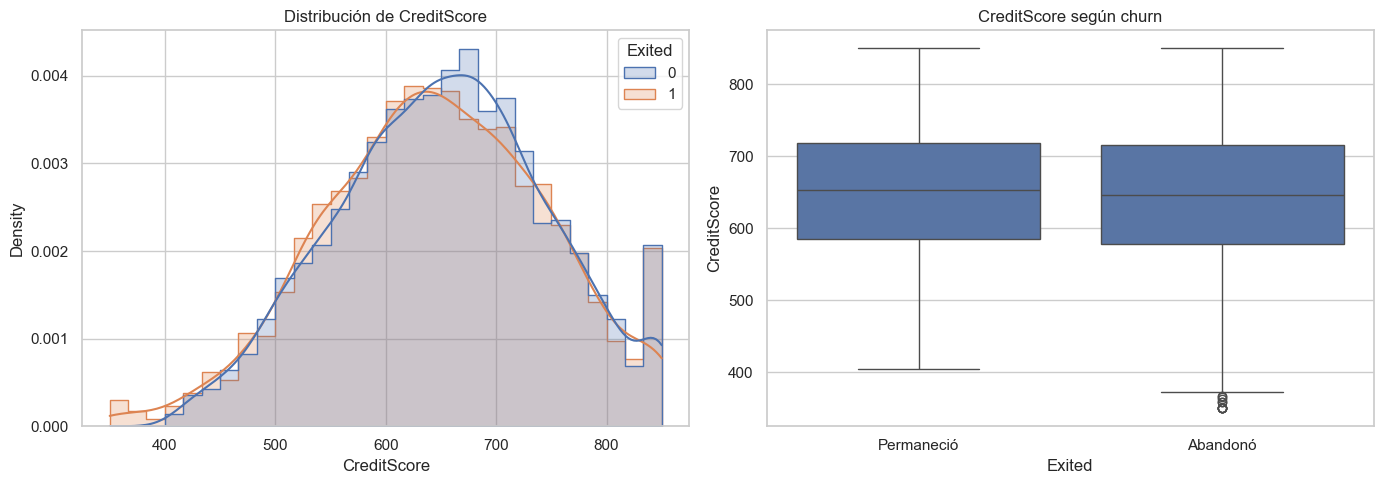

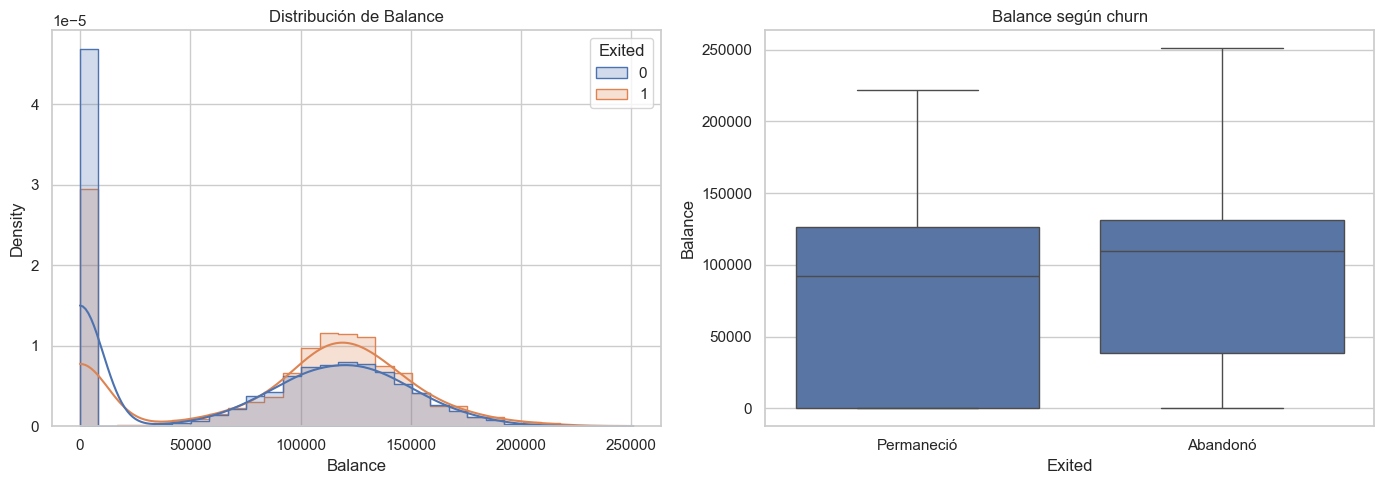

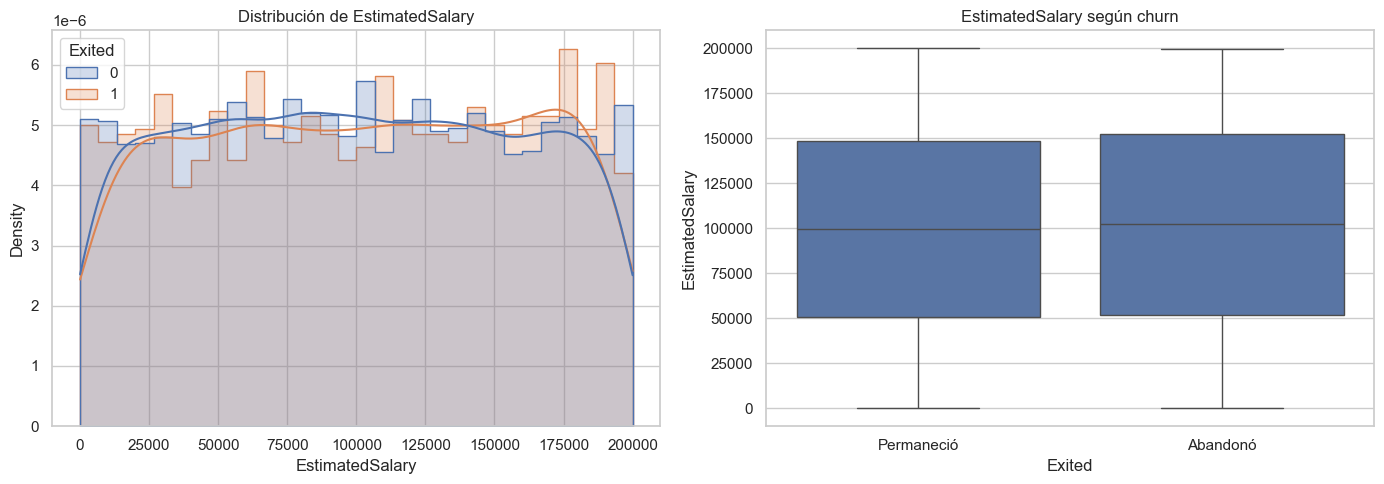

In [33]:
# Distribuciones de las variables financieras
for variable in variables_financieras:

    fig, ejes = plt.subplots(
        1,
        2,
        figsize=(14, 5)
    )

    # Distribución

    sns.histplot(
        data=df,
        x=variable,
        hue="Exited",
        bins=30,
        kde=True,
        stat="density",
        common_norm=False,
        element="step",
        ax=ejes[0]
    )

    ejes[0].set_title(
        f"Distribución de {variable}"
    )

    # Boxplot

    sns.boxplot(
        data=df,
        x="Exited",
        y=variable,
        ax=ejes[1]
    )

    ejes[1].set_title(
        f"{variable} según churn"
    )

    ejes[1].set_xticks(
        [0, 1]
    )

    ejes[1].set_xticklabels([
        "Permaneció",
        "Abandonó"
    ])

    plt.tight_layout()

    plt.show()

El puntaje crediticio promedio es levemente inferior entre los clientes que abandonaron el banco. Sin embargo, la diferencia observada es pequeña.

El saldo promedio es mayor entre los clientes que abandonaron. Esta diferencia sugiere que la variable `Balance` podría aportar información relevante al modelo.

Los valores promedio y las distribuciones del salario estimado son similares entre ambas clases, por lo que no se observa una diferencia descriptiva marcada.

Estas observaciones son preliminares y deberán analizarse junto con las demás variables mediante el modelo multivariable.

##### 4.4 Clientes con Saldo cero

Como inicialmente se detectaron 3617 casos de 10000 clientes, es conveniente analizarlos.

In [34]:
# Creación temporal de una categoría para comparar clientes con y sin saldo
analisis_saldo_cero = (
    df
    .assign(
        Estado_balance=np.where(
            df["Balance"].eq(0),
            "Saldo igual a cero",
            "Saldo mayor que cero"
        )
    )
)

churn_saldo_cero = (
    resumen_churn_por_categoria(
        analisis_saldo_cero,
        "Estado_balance"
    )
)

churn_saldo_cero

,Estado_balance,Cantidad_clientes,Clientes_que_abandonaron,Tasa_de_churn (%)
0,Saldo igual a cero,3617,500,13.82
1,Saldo mayor que cero,6383,1537,24.08


Los clientes con saldo igual a cero presentan una tasa de abandono de 13,82%, mientras que los clientes con saldo mayor que cero registran una tasa de 24,08%.

Los valores iguales a cero no se consideran datos faltantes ni errores. Representan un grupo válido de clientes, ya que parecen contener información relevante para la predicción del abandono.

##### 4.5 Cantidad de Productos Contratados

In [35]:
# Tasa de churn según número de productos
churn_productos = (
    resumen_churn_por_categoria(
        df,
        "NumOfProducts"
    )
)

churn_productos

,NumOfProducts,Cantidad_clientes,Clientes_que_abandonaron,Tasa_de_churn (%)
0,1,5084,1409,27.71
1,2,4590,348,7.58
2,3,266,220,82.71
3,4,60,60,100.00


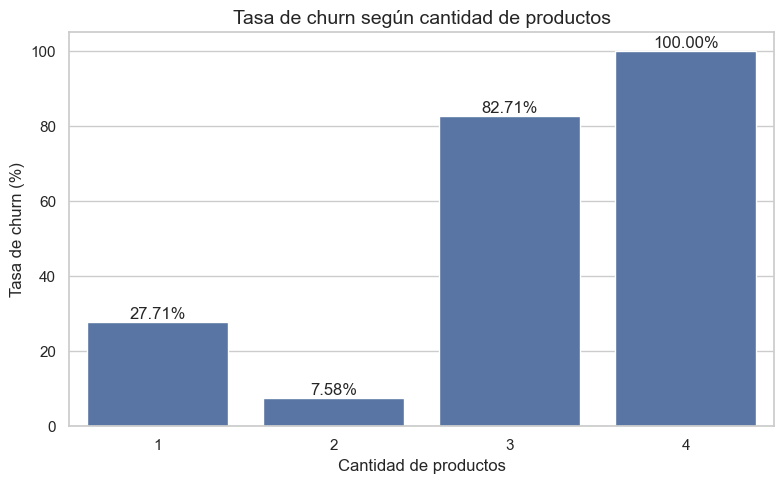

In [36]:
# Tasa de churn según productos contratados
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=churn_productos,
    x="NumOfProducts",
    y="Tasa_de_churn (%)"
)

plt.title(
    "Tasa de churn según cantidad de productos",
    fontsize=14
)

plt.xlabel(
    "Cantidad de productos"
)

plt.ylabel(
    "Tasa de churn (%)"
)

for barra in ax.patches:

    valor = barra.get_height()

    ax.annotate(
        f"{valor:.2f}%",
        (
            barra.get_x()
            + barra.get_width() / 2,
            valor
        ),
        ha="center",
        va="bottom"
    )

plt.tight_layout()

plt.show()

Los clientes con dos productos presentan la menor tasa de abandono, cercana al 7,58%.

Los clientes con un producto muestran una tasa mayor, aproximadamente del 27,71%. 

Por otra parte, las tasas observadas para tres y cuatro productos son muy elevadas.

Sin embargo, los grupos de tres y cuatro productos contienen únicamente 266 y 60 clientes, respectivamente. Por lo cual, los porcentajes se deben interpretarse con cuidado, dado a que la muestra es muy pequeña.

La relación observada podría no ser completamente lineal, aspecto que representa una posible limitación para un modelo lineal como la Regresión Logística.

##### 4.6 Tarjeta de Crédito y Membresía Activa

In [37]:
# Tasa de churn según si tiene o no tarjeta de crédito
churn_tarjeta = (
    resumen_churn_por_categoria(
        df,
        "HasCrCard"
    )
)

churn_tarjeta

,HasCrCard,Cantidad_clientes,Clientes_que_abandonaron,Tasa_de_churn (%)
0,0,2945,613,20.81
1,1,7055,1424,20.18


In [38]:
# Tasa de churn según actividad
churn_actividad = (
    resumen_churn_por_categoria(
        df,
        "IsActiveMember"
    )
)

churn_actividad

,IsActiveMember,Cantidad_clientes,Clientes_que_abandonaron,Tasa_de_churn (%)
0,0,4849,1302,26.85
1,1,5151,735,14.27


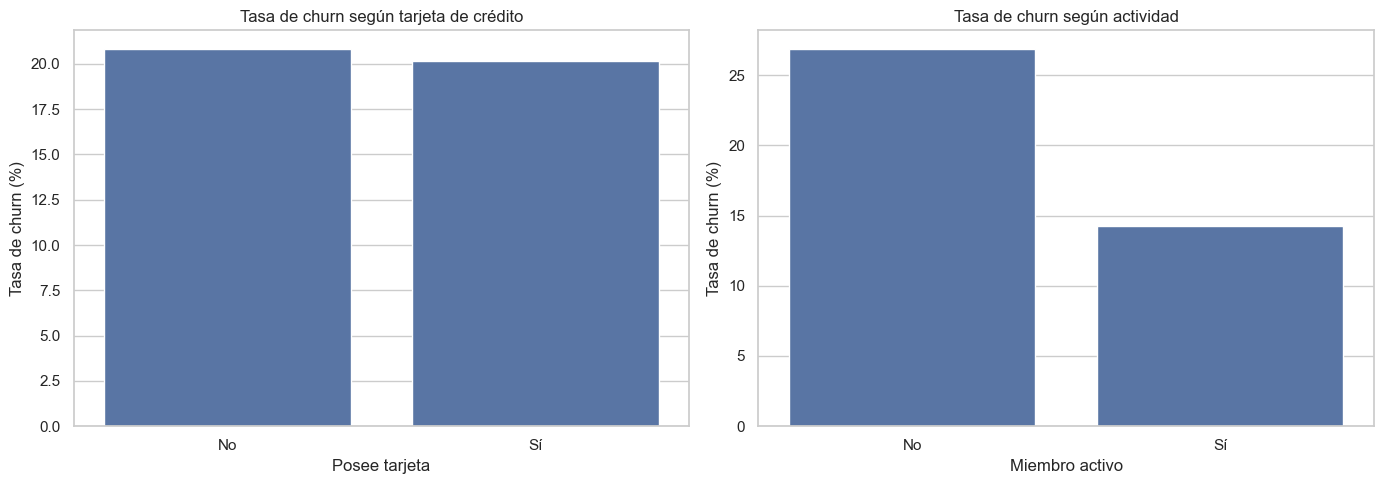

In [39]:
# Gráfico para Comparar los casos

fig, ejes = plt.subplots(
    1,
    2,
    figsize=(14, 5)
)

sns.barplot(
    data=churn_tarjeta,
    x="HasCrCard",
    y="Tasa_de_churn (%)",
    ax=ejes[0]
)

ejes[0].set_title(
    "Tasa de churn según tarjeta de crédito"
)

ejes[0].set_xlabel(
    "Posee tarjeta"
)

ejes[0].set_ylabel(
    "Tasa de churn (%)"
)

ejes[0].set_xticks(
    [0, 1]
)

ejes[0].set_xticklabels([
    "No",
    "Sí"
])

sns.barplot(
    data=churn_actividad,
    x="IsActiveMember",
    y="Tasa_de_churn (%)",
    ax=ejes[1]
)

ejes[1].set_title(
    "Tasa de churn según actividad"
)

ejes[1].set_xlabel(
    "Miembro activo"
)

ejes[1].set_ylabel(
    "Tasa de churn (%)"
)

ejes[1].set_xticks(
    [0, 1]
)

ejes[1].set_xticklabels([
    "No",
    "Sí"
])

plt.tight_layout()

plt.show()

La tasa de churn es muy similar entre quienes poseen y quienes no poseen tarjeta de crédito. Por lo tanto, no se observa una asociación descriptiva importante para esta variable.

Por el otro lado, los clientes que no son miembros activos presentan una tasa de abandono cercana al 26,85%, mientras que los miembros activos registran aproximadamente un 14,27%.

La condición de miembro activo parece estar asociada con una menor tasa de churn y podría constituir una variable relevante para el modelo.

##### 4.7 Revisión estadística de valores atípicos

Se utilizará el rango intercuartílico (IQR) como método exploratorio para identificar observaciones alejadas de la distribución central.

La detección estadística de un valor atípico no implica que el registro sea incorrecto. Antes de eliminar datos es necesario evaluar su validez y qué significado tiene dentro del abandono de clientes.

In [40]:
# Identificación de posibles valores atípicos por el metodo del rango intercuartílico
variables_revision_outliers = [
    "CreditScore",
    "Age",
    "Tenure",
    "Balance",
    "NumOfProducts",
    "EstimatedSalary"
]

resultados_outliers = []

for variable in variables_revision_outliers:

    q1 = df[variable].quantile(0.25)

    q3 = df[variable].quantile(0.75)

    iqr = q3 - q1

    limite_inferior = (
        q1 - 1.5 * iqr
    )

    limite_superior = (
        q3 + 1.5 * iqr
    )

    cantidad = (
        (
            df[variable]
            < limite_inferior
        )
        |
        (
            df[variable]
            > limite_superior
        )
    ).sum()

    resultados_outliers.append({

        "Variable": variable,

        "Límite inferior":
            round(
                limite_inferior,
                2
            ),

        "Límite superior":
            round(
                limite_superior,
                2
            ),

        "Posibles outliers":
            cantidad,

        "Porcentaje (%)":
            round(
                cantidad
                / len(df)
                * 100,
                2
            )
    })

tabla_outliers = pd.DataFrame(
    resultados_outliers
)

tabla_outliers

,Variable,Límite inferior,Límite superior,Posibles outliers,Porcentaje (%)
0,CreditScore,383.00,919.00,15,0.15
1,Age,14.00,62.00,359,3.59
2,Tenure,-3.00,13.00,0,0.00
3,Balance,"-191,466.36","319,110.60",0,0.00
4,NumOfProducts,-0.50,3.50,60,0.60
5,EstimatedSalary,"-96,577.10","296,967.45",0,0.00


El método IQR identifica posibles valores atípicos en `CreditScore`, `Age` y `NumOfProducts`.

No obstante, los valores observados se encuentran dentro de rangos posibles:

- Los puntajes crediticios bajos son valores válidos.
- Las edades elevadas corresponden a clientes posibles y no presentan errores evidentes.
- Los casos identificados en `NumOfProducts` corresponden a clientes con cuatro productos contratados.

Conclusión, no se eliminarán observaciones solamente por haber sido identificadas como atípicas por medio de un criterio estadístico.

##### 4.8 Correlaciones y Multicolinealidad

Se analizarán las correlaciones lineales entre las variables numéricas candidatas para el modelo.

El objetivo:

- Identificar posibles relaciones con la variable objetivo.
- Identificar variables predictoras altamente correlacionadas entre sí.
- Identificar posibles problemas de multicolinealidad.

In [41]:
# Variables numéricas candidatas
variables_correlacion = [
    "CreditScore",
    "Age",
    "Tenure",
    "Balance",
    "NumOfProducts",
    "HasCrCard",
    "IsActiveMember",
    "EstimatedSalary",
    "Exited"
]

matriz_correlacion = (
    df[
        variables_correlacion
    ]
    .corr()
)

matriz_correlacion.round(2)

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
CreditScore,1.00,-0.00,0.00,0.01,0.01,-0.01,0.03,-0.00,-0.03
Age,-0.00,1.00,-0.01,0.03,-0.03,-0.01,0.09,-0.01,0.29
Tenure,0.00,-0.01,1.00,-0.01,0.01,0.02,-0.03,0.01,-0.01
Balance,0.01,0.03,-0.01,1.00,-0.30,-0.01,-0.01,0.01,0.12
NumOfProducts,0.01,-0.03,0.01,-0.30,1.00,0.00,0.01,0.01,-0.05
HasCrCard,-0.01,-0.01,0.02,-0.01,0.00,1.00,-0.01,-0.01,-0.01
IsActiveMember,0.03,0.09,-0.03,-0.01,0.01,-0.01,1.00,-0.01,-0.16
EstimatedSalary,-0.00,-0.01,0.01,0.01,0.01,-0.01,-0.01,1.00,0.01
Exited,-0.03,0.29,-0.01,0.12,-0.05,-0.01,-0.16,0.01,1.00


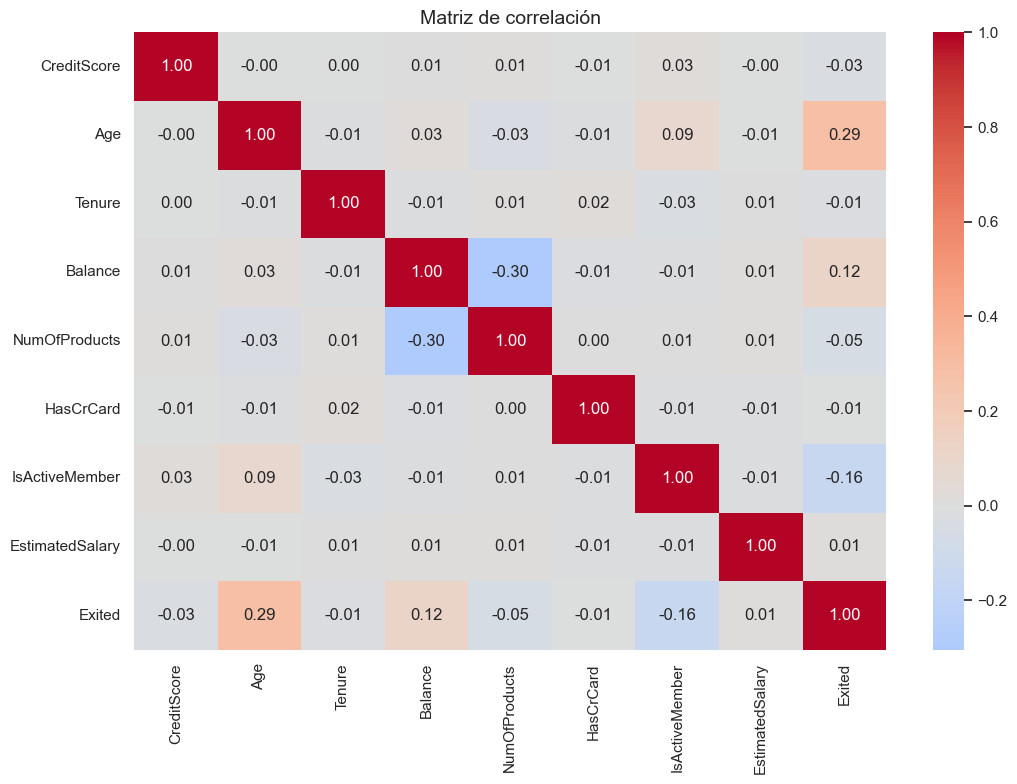

In [42]:
# Mapa de calor de correlaciones
plt.figure(
    figsize=(11, 8)
)

sns.heatmap(
    matriz_correlacion,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title(
    "Matriz de correlación",
    fontsize=14
)

plt.tight_layout()

plt.show()

In [43]:
# Buscar correlaciones altas entre variables predictoras
variables_predictoras_numericas = [
    variable
    for variable
    in variables_correlacion
    if variable != "Exited"
]

correlacion_predictoras = (
    df[
        variables_predictoras_numericas
    ]
    .corr()
    .abs()
)

triangulo_superior = (
    correlacion_predictoras
    .where(
        np.triu(
            np.ones(
                correlacion_predictoras.shape
            ),
            k=1
        ).astype(bool)
    )
)

correlaciones_altas = (
    triangulo_superior
    .stack()
    .reset_index()
)

correlaciones_altas.columns = [
    "Variable 1",
    "Variable 2",
    "Correlación absoluta"
]

correlaciones_altas = (
    correlaciones_altas[
        correlaciones_altas[
            "Correlación absoluta"
        ] >= 0.80
    ]
)

if correlaciones_altas.empty:

    print(
        "No se detectaron correlaciones "
        "absolutas iguales o superiores "
        "a 0.80."
    )

else:

    display(
        correlaciones_altas
    )

No se detectaron correlaciones absolutas iguales o superiores a 0.80.


##### 4.9 Conclusiones Generales del EDA

Con el análisis exploratorio se pudo identificar los siguientes hallazgos: 

1. La variable objetivo tiene un desbalance aproximado del 80% de clientes que permanecieron y 20% que abandonaron el banco.

2. Los clientes de mayor edad presentan una mayor frecuencia de abandono. La edad promedio es aproximadamente de 44,84 años entre quienes abandonaron y de 37,41 años entre quienes permanecieron.

3. Las clientas presentan una mayor tasa de churn que los hombres.

4. Alemania registra una tasa de abandono considerablemente superior a Francia y España.

5. Los clientes que no son miembros activos presentan una tasa de abandono mayor que los miembros activos.

6. El saldo promedio es superior entre los clientes que abandonaron. Los clientes con saldo mayor que cero también presentan una tasa de churn superior a quienes poseen saldo igual a cero.

7. La cantidad de productos muestra una relación no lineal con el abandono. Los clientes con dos productos presentan la menor tasa de churn, mientras que los grupos con tres y cuatro productos registran tasas elevadas. Estos últimos resultados deben interpretarse con cautela debido a la reducida cantidad de observaciones.

8. La posesión de tarjeta de crédito, la antigüedad y el salario estimado no muestran diferencias descriptivas entre las clases.

9. Se identificaron posibles valores atípicos mediante el método IQR, pero no se detectaron valores evidentemente inválidos. Por lo cual, no se eliminarán observaciones en esta etapa.

10. No se observaron correlaciones elevadas entre las variables predictoras numéricas, por lo que no existen indicios iniciales de multicolinealidad severa.

Estos resultados son descriptivos y no implican relaciones causales. 
La Regresión Logística permitirá analizar el efecto conjunto de las variables sobre la probabilidad de abandono.

#### 5. Selección y Preparación de Variables

Antes de entrenar la Regresión Logística, se deben seleccionar las variables que aportan información sobre las características demográficas, financieras y de relación de los clientes con el banco.

Se excluirán las siguientes columnas:

- `RowNumber`: representa únicamente el número de fila.
- `CustomerId`: es un identificador único del cliente.
- `Surname`: contiene el apellido del cliente y presenta una cardinalidad elevada.

Estas variables no describen características del comportamiento de los clientes y podrían introducir ruido en el modelo.

La variable objetivo será `Exited`, donde:

- **0**: el cliente permaneció en el banco.
- **1**: el cliente abandonó el banco.

##### 5.1 Definición de X e Y

In [44]:
# Columnas que no serán utilizadas como variables predictoras
columnas_excluidas = [
    "RowNumber",
    "CustomerId",
    "Surname"
]

# Variables predictoras

X = df.drop(
    columns=columnas_excluidas + ["Exited"]
)

# Variable objetivo

y = df["Exited"]

print("Dimensiones de las variables predictoras:")
print(X.shape)

print("\nDimensiones de la variable objetivo:")
print(y.shape)

print("\nVariables seleccionadas:")

for numero, variable in enumerate(
    X.columns,
    start=1
):
    print(
        f"{numero}. {variable}"
    )

Dimensiones de las variables predictoras:
(10000, 10)

Dimensiones de la variable objetivo:
(10000,)

Variables seleccionadas:
1. CreditScore
2. Geography
3. Gender
4. Age
5. Tenure
6. Balance
7. NumOfProducts
8. HasCrCard
9. IsActiveMember
10. EstimatedSalary


Luego de excluir las columnas que se utilizan como índices o identificadores, el conjunto de variables predictoras quedó compuesto por 10 características.

Las variables seleccionadas incluyen información demográfica, financiera y de relación con el banco. La variable `Exited` se separó del conjunto de predictores y será utilizada como variable objetivo.

##### 5.2 División entre Entrenamiento y Prueba

In [45]:
# Herramienta para dividir el dataset

from sklearn.model_selection import train_test_split

In [46]:
# División del dataset: 80% entrenamiento y 20% prueba

X_train, X_test, y_train, y_test = (
    train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=42,
        stratify=y
    )
)

print(
    f"Registros de entrenamiento: "
    f"{X_train.shape[0]:,}"
)

print(
    f"Registros de prueba: "
    f"{X_test.shape[0]:,}"
)

print(
    f"\nVariables predictoras: "
    f"{X_train.shape[1]}"
)

Registros de entrenamiento: 8,000
Registros de prueba: 2,000

Variables predictoras: 10


##### 5.3 Verificación de la Estratificación

In [47]:
# Comparación de la distribución de clases
distribucion_split = pd.DataFrame({
    "Dataset completo (%)": (
        y
        .value_counts(
            normalize=True
        )
        .sort_index()
        * 100
    ),

    "Entrenamiento (%)": (
        y_train
        .value_counts(
            normalize=True
        )
        .sort_index()
        * 100
    ),

    "Prueba (%)": (
        y_test
        .value_counts(
            normalize=True
        )
        .sort_index()
        * 100
    )
}).round(2)

distribucion_split.index = [
    "Permaneció (0)",
    "Abandonó (1)"
]

distribucion_split

,Dataset completo (%),Entrenamiento (%),Prueba (%)
Permaneció (0),79.63,79.62,79.65
Abandonó (1),20.37,20.38,20.35


El dataset se dividió utilizando el 80% de los registros para entrenamiento y el 20% para prueba.

Se aplicó estratificación sobre la variable objetivo para conservar una proporción similar de clientes que no abandonaron y abandonaron en ambos conjuntos.

La proporción de la clase positiva se mantiene cercana al 20% tanto en entrenamiento como en prueba. Esto hace que se pueda realizar una evaluación más representativa y evita que una de las particiones presente una distribución de clases diferente a la observada en el dataset original.

#### 6. Preprocesamiento de Variables

La Regresión Logística requiere que las variables utilizadas durante el entrenamiento se encuentren representadas numéricamente.

El preprocesamiento se realizará según el tipo de variable:

- Las variables numéricas serán estandarizadas mediante `StandardScaler`.
- Las variables categóricas serán transformadas mediante One-Hot Encoding.
- Las variables binarias ya se encuentran codificadas como 0 y 1; por lo tanto, conservarán sus valores originales.

El preprocesador se ajustará exclusivamente utilizando el conjunto de entrenamiento. Luego, las mismas transformaciones aprendidas serán aplicadas al conjunto de prueba. Este procedimiento evita la fuga de información.

##### 6.1 Clasificación de las Variables

In [48]:
# Variables numéricas que serán estandarizadas
variables_numericas = [
    "CreditScore",
    "Age",
    "Tenure",
    "Balance",
    "NumOfProducts",
    "EstimatedSalary"
]

# Variables categóricas
variables_categoricas = [
    "Geography",
    "Gender"
]

# Variables binarias ya codificadas
variables_binarias = [
    "HasCrCard",
    "IsActiveMember"
]

print("Variables numéricas:")
print(variables_numericas)

print("\nVariables categóricas:")
print(variables_categoricas)

print("\nVariables binarias:")
print(variables_binarias)

Variables numéricas:
['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'EstimatedSalary']

Variables categóricas:
['Geography', 'Gender']

Variables binarias:
['HasCrCard', 'IsActiveMember']


##### 6.2 Creación del Preprocesador

In [49]:
# Primero importamos las herramientas para el preprocesamiento

from sklearn.compose import ColumnTransformer

from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)

In [50]:
# Transformador las Variables Categóricas
transformador_categorico = (
    OneHotEncoder(
        drop="first",
        handle_unknown="ignore",
        sparse_output=False
    )
)

# Preprocesador general
preprocesador = ColumnTransformer(
    transformers=[

        (
            "numericas",
            StandardScaler(),
            variables_numericas
        ),

        (
            "categoricas",
            transformador_categorico,
            variables_categoricas
        ),

        (
            "binarias",
            "passthrough",
            variables_binarias
        )
    ],

    verbose_feature_names_out=False
)

print(
    "Preprocesador creado correctamente."
)

Preprocesador creado correctamente.


##### 6.3 Ajuste y Transformación

In [51]:
# Ajuste del preprocesador usando solamente los datos de entrenamiento
X_train_preparado = (
    preprocesador
    .fit_transform(
        X_train
    )
)

# Aplicación de las transformaciones aprendidas al conjunto de prueba
X_test_preparado = (
    preprocesador
    .transform(
        X_test
    )
)

print(
    "Datos transformados correctamente."
)

print(
    "\nDimensiones de entrenamiento:"
)

print(
    X_train_preparado.shape
)

print(
    "\nDimensiones de prueba:"
)

print(
    X_test_preparado.shape
)

Datos transformados correctamente.

Dimensiones de entrenamiento:
(8000, 11)

Dimensiones de prueba:
(2000, 11)


##### 6.4 Recuperar los Nombres de las Variables

In [52]:
# Los nombres de las variables luego del preprocesamiento
nombres_variables_modelo = (
    preprocesador
    .get_feature_names_out()
)

print(
    "Variables utilizadas por el modelo:"
)

for numero, variable in enumerate(
    nombres_variables_modelo,
    start=1
):
    print(
        f"{numero}. {variable}"
    )

Variables utilizadas por el modelo:
1. CreditScore
2. Age
3. Tenure
4. Balance
5. NumOfProducts
6. EstimatedSalary
7. Geography_Germany
8. Geography_Spain
9. Gender_Male
10. HasCrCard
11. IsActiveMember


##### 6.5 Visualización de los Datos Preparados

In [53]:
# Conversión temporal a DataFrame para que sea más facil la visualización
X_train_preparado_df = pd.DataFrame(
    X_train_preparado,
    columns=nombres_variables_modelo,
    index=X_train.index
)

X_train_preparado_df.head()

,CreditScore,Age,Tenure,Balance,NumOfProducts,EstimatedSalary,Geography_Germany,Geography_Spain,Gender_Male,HasCrCard,IsActiveMember
2151,1.06,1.72,0.68,-1.23,-0.91,1.04,0.00,0.00,1.00,1.00,0.00
8392,0.91,-0.66,-0.70,0.41,-0.91,-0.62,1.00,0.00,1.00,1.00,0.00
5006,1.08,-0.18,-1.73,0.60,0.81,0.31,1.00,0.00,0.00,1.00,1.00
4117,-0.93,-0.18,-0.01,-1.23,0.81,-0.29,0.00,0.00,1.00,1.00,0.00
7182,0.43,0.96,0.34,0.55,0.81,0.14,1.00,0.00,1.00,0.00,1.00


Se puede observar que las variables numéricas tienen valores positivos y negativos porque fueron estandarizadas. A su vez, las variables categóricas aparecen transformadas en columnas binarias. Y, `HasCrCard`e `IsActiveMember`mantienen sus valores originales.

##### 6.6 Verificación del Escalamiento

In [54]:
# Verificación aprox del escalamiento
verificacion_escalamiento = (
    X_train_preparado_df[
        variables_numericas
    ]
    .agg([
        "mean",
        "std"
    ])
    .round(2)
)

verificacion_escalamiento

,CreditScore,Age,Tenure,Balance,NumOfProducts,EstimatedSalary
mean,-0.00,0.00,-0.00,0.00,-0.00,-0.00
std,1.00,1.00,1.00,1.00,1.00,1.00


##### 6.7 Conclusión del Preprocesamiento

La preparación de los datos se hizó respetando la división entre entrenamiento y prueba.

Las principales decisiones fueron:

1. Se excluyeron `RowNumber`, `CustomerId` y `Surname`, debido a que funcionan como identificadores y no representan características comportamiento de los clientes.

2. El dataset se dividió en 80% para entrenamiento y 20% para prueba.

3. Se utilizó estratificación para conservar la proporción aproximada de las clases en ambos conjuntos.

4. Las variables numéricas fueron estandarizadas mediante **StandardScaler**.

5. Las variables `Geography` y `Gender` fueron transformadas mediante **One-Hot Encoding**.

6. Las variables binarias `HasCrCard` e `IsActiveMember` conservaron su codificación original de 0 y 1.

7. El preprocesador fue ajustado exclusivamente con los datos de entrenamiento y luego, aplicado al conjunto de prueba, evitando la fuga de información.

Luego de las transformaciones, el conjunto de entrenamiento contiene 8.000 registros y 11 características, mientras que el conjunto de prueba contiene 2.000 registros y las mismas 11 características.

Los datos se encuentran preparados para el entrenamiento de la Regresión Logística.

#### 7. Entrenamiento de la Regresión Logística

La Regresión Logística es un algoritmo de aprendizaje supervisado que se usa para problemas de clasificación.

En este proyecto, el modelo estimará la probabilidad de que un cliente abandone el banco:

- `Exited = 0`: el cliente permanece.
- `Exited = 1`: el cliente abandona.

El modelo parte de una combinación lineal de las variables predictoras:

\[
z = \beta_0 + \beta_1X_1 + \beta_2X_2 + \cdots + \beta_nX_n
\]

Luego, se utiliza la función sigmoide para transformar el resultado en una probabilidad comprendida entre 0 y 1:

\[
P(Y=1) = \frac{1}{1 + e^{-z}}
\]

De forma predeterminada, el modelo utiliza un umbral de 0,50:

- Probabilidad menor que 0,50 → predicción `0`.
- Probabilidad mayor o igual que 0,50 → predicción `1`.

La Regresión Logística será utilizada como modelo baseline, es decir, como punto de referencia para comparar posteriormente modelos de mayor complejidad.

##### 7.1 Importación y Creación del Modelo 

In [55]:
# Importar modelo
from sklearn.linear_model import LogisticRegression

In [56]:
# Creación del Modelo Baseline
modelo_logistico = LogisticRegression(
    solver="lbfgs",
    max_iter=1000
)

print(
    "Modelo de Regresión Logística "
    "creado correctamente."
)

Modelo de Regresión Logística creado correctamente.


##### 7.2 Entrenamiento

In [57]:
# Entrenamiento del modelo usando los datos ya preparados

modelo_logistico.fit(
    X_train_preparado,
    y_train
)

print(
    "Modelo entrenado correctamente."
)

Modelo entrenado correctamente.


##### 7.3 Verificación de la Convergencia

In [58]:
# Cantidad de iteraciones usadas
print(
    "Iteraciones utilizadas:",
    modelo_logistico.n_iter_[0]
)

Iteraciones utilizadas: 15


##### 7.4 Generación de Predicciones

Se generarán dos tipos de resultados:

1. **Predicción de clase:** indica si el modelo clasifica al cliente como alguien que permanecerá o abandonará el banco.

2. **Probabilidad de churn:** representa la probabilidad estimada de que el cliente pertenezca a la clase positiva `Exited = 1`.

In [59]:
# Predicciones de clase
y_pred = modelo_logistico.predict(
    X_test_preparado
)

# Probabilidad que corresponde a la clase positiva Exited = 1
y_prob = (
    modelo_logistico
    .predict_proba(
        X_test_preparado
    )[:, 1]
)

print(
    "Predicciones generadas correctamente."
)

print(
    f"Cantidad de predicciones: "
    f"{len(y_pred):,}"
)

Predicciones generadas correctamente.
Cantidad de predicciones: 2,000


##### 7.5 Visualización de algunas Predicciones

In [60]:
# Comparacion entre valores reales, predicciones y probabilidades

comparacion_predicciones = pd.DataFrame({

    "Valor real":
        y_test.values,

    "Predicción":
        y_pred,

    "Probabilidad de churn":
        y_prob

})

comparacion_predicciones.head(10)

,Valor real,Predicción,Probabilidad de churn
0,0,0,0.12
1,0,0,0.28
2,0,0,0.11
3,0,0,0.15
4,0,0,0.10
5,0,0,0.14
6,0,0,0.09
7,0,0,0.36
8,0,0,0.36
9,0,0,0.21


El modelo genera inicialmente una probabilidad de abandono para cada cliente.

Luego, usando el umbral predeterminado de 0,50, transforma las probabilidades en clases:

- Si la probabilidad es menor que 0,50, predice que el cliente permanecerá en el banco.
- Si la probabilidad es igual o mayor que 0,50, predice que el cliente abandonará el banco.

La probabilidad contiene más información que la clasificación final, ya que permite conocer el nivel de riesgo estimado para cada cliente.

#### 8. Evaluación del Modelo

El rendimiento del modelo se evaluará usando diferentes métricas de clasificación binaria.

Debido al desbalance de la variable objetivo, no se utilizará únicamente la accuracy. También se analizarán:

- Precision
- Recall
- F1-score
- Matriz de confusión
- Curva ROC
- Área bajo la curva ROC (ROC-AUC)

La clase positiva será `Exited = 1`, que corresponde a los clientes que abandonaron el banco.

##### 8.1 Importación de Métricas

In [61]:
# Métricas de clasificación
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    roc_curve
)

##### 8.2 Cálculo de las Métricas Principales

In [62]:
# Cálculo de métricas

accuracy = accuracy_score(
    y_test,
    y_pred
)

precision = precision_score(
    y_test,
    y_pred
)

recall = recall_score(
    y_test,
    y_pred
)

f1 = f1_score(
    y_test,
    y_pred
)

roc_auc = roc_auc_score(
    y_test,
    y_prob
)

# Creación de una tabla
metricas_modelo = pd.DataFrame({

    "Métrica": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC"
    ],

    "Resultado": [
        accuracy,
        precision,
        recall,
        f1,
        roc_auc
    ]

})

metricas_modelo[
    "Resultado"
] = metricas_modelo[
    "Resultado"
].round(4)

metricas_modelo

,Métrica,Resultado
0,Accuracy,0.81
1,Precision,0.59
2,Recall,0.19
3,F1-score,0.28
4,ROC-AUC,0.77


##### 8.3 Reporte Completo de Clasificación

In [63]:
# Reporte detallado por cada clase
reporte_clasificacion = (
    classification_report(
        y_test,
        y_pred,
        target_names=[
            "Permaneció (0)",
            "Abandonó (1)"
        ],
        output_dict=True
    )
)

reporte_clasificacion_df = (
    pd.DataFrame(
        reporte_clasificacion
    )
    .T
    .round(3)
)

reporte_clasificacion_df

,precision,recall,f1-score,support
Permaneció (0),0.82,0.97,0.89,"1,593.00"
Abandonó (1),0.59,0.19,0.28,407.00
accuracy,0.81,0.81,0.81,0.81
macro avg,0.71,0.58,0.59,"2,000.00"
weighted avg,0.78,0.81,0.77,"2,000.00"


##### 8.4 Matriz de Confusión

La matriz de confusión permite identificar los diferentes tipos de aciertos y errores del modelo:

- **Verdadero negativo (TN):** el cliente permaneció y el modelo predijo que permanecería.
- **Falso positivo (FP):** el cliente permaneció, pero el modelo predijo que abandonaría.
- **Falso negativo (FN):** el cliente abandonó, pero el modelo predijo que permanecería.
- **Verdadero positivo (TP):** el cliente abandonó y el modelo detectó correctamente el abandono.

In [64]:
# Cálculo de la matriz de confusión
matriz_confusion = confusion_matrix(
    y_test,
    y_pred
)

# Extracción de sus componentes
tn, fp, fn, tp = (
    matriz_confusion.ravel()
)

print(
    f"Verdaderos negativos: {tn}"
)

print(
    f"Falsos positivos: {fp}"
)

print(
    f"Falsos negativos: {fn}"
)

print(
    f"Verdaderos positivos: {tp}"
)

Verdaderos negativos: 1540
Falsos positivos: 53
Falsos negativos: 331
Verdaderos positivos: 76


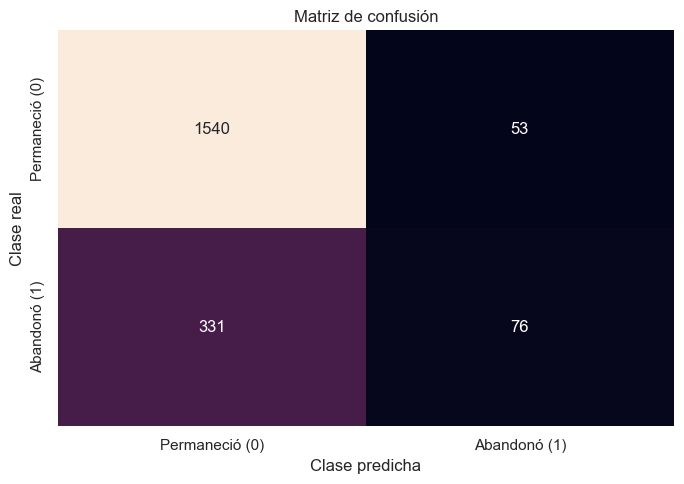

In [65]:
# Gráfico de la matriz de confusión

plt.figure(
    figsize=(7, 5)
)

sns.heatmap(
    matriz_confusion,
    annot=True,
    fmt="d",
    cbar=False,
    xticklabels=[
        "Permaneció (0)",
        "Abandonó (1)"
    ],
    yticklabels=[
        "Permaneció (0)",
        "Abandonó (1)"
    ]
)

plt.title(
    "Matriz de confusión"
)

plt.xlabel(
    "Clase predicha"
)

plt.ylabel(
    "Clase real"
)

plt.tight_layout()

plt.show()

##### 8.5 Curva ROC y AUC

La curva ROC evalúa la capacidad del modelo para distinguir entre clientes que permanecen y clientes que abandonan considerando diferentes umbrales de clasificación.

El ROC-AUC resume el rendimiento mediante un valor entre 0 y 1:

- **0,50**: capacidad similar al azar.
- Valores mayores que **0,50**: el modelo tiene la capacidad de discriminación.
- Valores cercanos a **1**: alta capacidad para separar las clases.

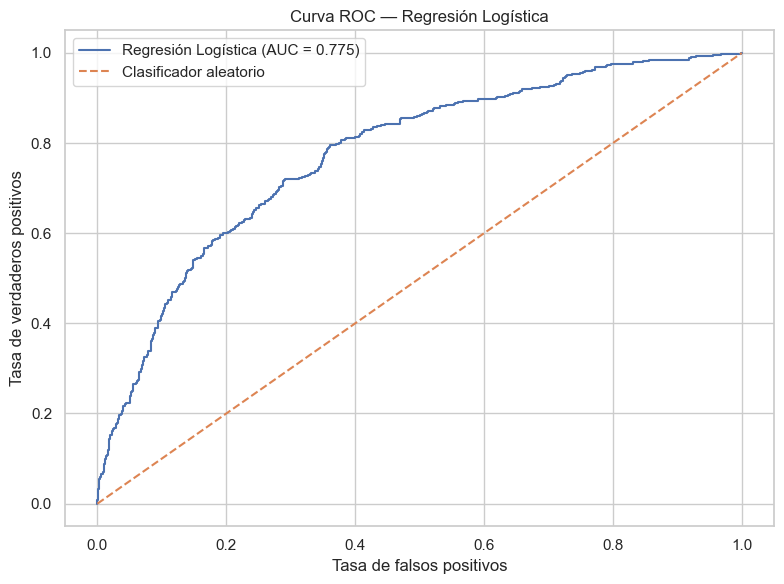

In [66]:
# Cálculo de la curva ROC
fpr, tpr, umbrales = roc_curve(
    y_test,
    y_prob
)

# Gráfico
plt.figure(
    figsize=(8, 6)
)

plt.plot(
    fpr,
    tpr,
    label=(
        f"Regresión Logística "
        f"(AUC = {roc_auc:.3f})"
    )
)

# Línea de referencia aleatoria
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Clasificador aleatorio"
)

plt.title(
    "Curva ROC — Regresión Logística"
)

plt.xlabel(
    "Tasa de falsos positivos"
)

plt.ylabel(
    "Tasa de verdaderos positivos"
)

plt.legend()

plt.tight_layout()

plt.show()

##### 8.6 Comparación entre Entrenamiento y Prueba

In [67]:
# Predicciones sobre el entrenamiento
y_pred_train = (
    modelo_logistico
    .predict(
        X_train_preparado
    )
)

y_prob_train = (
    modelo_logistico
    .predict_proba(
        X_train_preparado
    )[:, 1]
)

# Tabla comparativa
comparacion_train_test = pd.DataFrame({

    "Métrica": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC"
    ],

    "Entrenamiento": [

        accuracy_score(
            y_train,
            y_pred_train
        ),

        precision_score(
            y_train,
            y_pred_train
        ),

        recall_score(
            y_train,
            y_pred_train
        ),

        f1_score(
            y_train,
            y_pred_train
        ),

        roc_auc_score(
            y_train,
            y_prob_train
        )

    ],

    "Prueba": [

        accuracy,

        precision,

        recall,

        f1,

        roc_auc

    ]

})

comparacion_train_test[
    [
        "Entrenamiento",
        "Prueba"
    ]
] = (
    comparacion_train_test[
        [
            "Entrenamiento",
            "Prueba"
        ]
    ]
    .round(4)
)

comparacion_train_test

,Métrica,Entrenamiento,Prueba
0,Accuracy,0.81,0.81
1,Precision,0.60,0.59
2,Recall,0.21,0.19
3,F1-score,0.32,0.28
4,ROC-AUC,0.77,0.77


##### 8.7 Interpretación de las Métricas

La evaluación debe analizarse considerando el desbalance de la variable objetivo. Debido a que aproximadamente el 80% de los clientes permaneció en el banco, una accuracy elevada no garantiza por sí sola una buena capacidad para detectar clientes con riesgo de abandono.

Las métricas se interpretan de la siguiente manera:

- **Accuracy**: proporción total de predicciones correctas.
- **Precision**: de todos los clientes clasificados como posibles abandonos, indica qué proporción realmente abandonó.
- **Recall**: de todos los clientes que realmente abandonaron, indica qué proporción se detectó por el modelo.
- **F1-score**: combina precision y recall mediante una media armónica.
- **ROC-AUC**: mide la capacidad del modelo para ordenar y diferenciar clientes que abandonan y clientes que permanecen, teniendo en cuenta los distintos umbrales de clasificación.

In [68]:
# Resumen de todas las métricas obtenidas

print("RESULTADOS DEL MODELO BASELINE")
print("-" * 40)

print(f"Accuracy:  {accuracy:.2%}")
print(f"Precision: {precision:.2%}")
print(f"Recall:    {recall:.2%}")
print(f"F1-score:  {f1:.2%}")
print(f"ROC-AUC:   {roc_auc:.4f}")

print("\nANÁLISIS DE LA CLASE POSITIVA")
print("-" * 40)

clientes_churn_reales = tp + fn

print(
    f"Clientes que realmente abandonaron: "
    f"{clientes_churn_reales}"
)

print(
    f"Clientes correctamente detectados: "
    f"{tp}"
)

print(
    f"Clientes no detectados: "
    f"{fn}"
)

print(
    f"Porcentaje de abandonos detectados: "
    f"{recall:.2%}"
)

RESULTADOS DEL MODELO BASELINE
----------------------------------------
Accuracy:  80.80%
Precision: 58.91%
Recall:    18.67%
F1-score:  28.36%
ROC-AUC:   0.7748

ANÁLISIS DE LA CLASE POSITIVA
----------------------------------------
Clientes que realmente abandonaron: 407
Clientes correctamente detectados: 76
Clientes no detectados: 331
Porcentaje de abandonos detectados: 18.67%


**Análisis del Rendimiento**

La Regresión Logística obtiene una **accuracy** cercana al 81%, lo que indica que clasifica correctamente una proporción elevada del total de clientes.

Sin embargo, esta métrica debe interpretarse con cautela debido al desbalance de clases. La mayoría de los clientes pertenece a la clase `Exited = 0`, por lo que una parte importante de los aciertos corresponde a clientes que permanecieron en el banco.

La **precision** de la clase positiva indica que una proporción moderada de los clientes clasificados como posibles abandonos realmente dejó el banco.

El **recall** es considerablemente menor. Esto significa que el modelo detecta solamente una parte de los clientes que realmente abandonaron y genera una cantidad elevada de falsos negativos.

Desde la perspectiva de negocio, los falsos negativos representan clientes que abandonaron el banco pero no fueron identificados previamente como clientes en riesgo. Este tipo de error puede limitar la capacidad del equipo de retención para intervenir de manera anticipada.

El **F1-score** refleja el desequilibrio existente entre precision y recall.

Por otra parte, el **ROC-AUC** muestra que el modelo posee capacidad para diferenciar clientes con distinto nivel de riesgo, aunque el desempeño todavía presenta margen de mejora.

Los resultados son consistentes con el objetivo de utilizar la Regresión Logística como modelo baseline.

#### 9. Interpretabilidad de la Regresión Logística

Una de las principales ventajas de la Regresión Logística es la posibilidad de interpretar la influencia de las variables sobre la probabilidad de pertenecer a la clase positiva.

El modelo trabaja internamente con los **log-odds**:

\[
\log\left(\frac{p}{1-p}\right)
=
\beta_0
+
\beta_1X_1
+
\beta_2X_2
+
\cdots
+
\beta_nX_n
\]

Donde:

- \(p\) representa la probabilidad de que `Exited = 1`.
- \(\frac{p}{1-p}\) representa los odds de abandono.
- \(\beta_0\) es el intercepto.
- \(\beta_i\) representa el coeficiente asociado a cada variable.

Un coeficiente positivo aumenta los log-odds de abandono, mientras que un coeficiente negativo los disminuye.

Para facilitar la interpretación, los coeficientes pueden transformarse en odds ratios mediante:

\[
OR = e^{\beta}
\]

##### 9.1 Conceptos de Probabilidad, odds y log-odds

La probabilidad muestra la posibilidad de que ocurra un evento mediante un valor comprendido entre 0 y 1.

Los odds comparan la probabilidad de que ocurra el evento con la probabilidad de que no ocurra:

\[
Odds =
\frac{p}{1-p}
\]

Ejemplo, si un cliente tiene una probabilidad de churn del 20%:

\[
Odds =
\frac{0.20}{1-0.20}
=
0.25
\]

Esto puede interpretarse como una relación de un abandono esperado por cada cuatro casos de permanencia.

Los log-odds se obtienen aplicando el logaritmo natural:

\[
LogOdds =
\log(Odds)
\]

La Regresión Logística modela los log-odds como una combinación lineal de las variables predictoras.

##### 9.2 Confirmación de las Categorías de Referencia

In [69]:
# Recuperación del codificador ya ajustado
encoder_ajustado = (
    preprocesador
    .named_transformers_[
        "categoricas"
    ]
)

print("CATEGORÍAS DE REFERENCIA")
print("-" * 40)

for variable, categorias, indice_referencia in zip(
    variables_categoricas,
    encoder_ajustado.categories_,
    encoder_ajustado.drop_idx_
):

    categoria_referencia = (
        categorias[indice_referencia]
    )

    print(
        f"{variable}: "
        f"{categoria_referencia}"
    )

CATEGORÍAS DE REFERENCIA
----------------------------------------
Geography: France
Gender: Female


##### 9.3 Extracción de Coeficientes y odds ratios

In [70]:
# Extracción de los coeficientes
coeficientes = (
    modelo_logistico
    .coef_[0]
)

# Cálculo de los odds ratios
odds_ratios = np.exp(
    coeficientes
)

# Cambio porcentual estimado en los odds
cambio_odds = (
    odds_ratios - 1
) * 100

# Tabla de interpretación
tabla_coeficientes = pd.DataFrame({

    "Variable":
        nombres_variables_modelo,

    "Coeficiente":
        coeficientes,

    "Odds ratio":
        odds_ratios,

    "Cambio estimado en odds (%)":
        cambio_odds

})

# Magnitud absoluta para ordenar las variables
tabla_coeficientes[
    "Magnitud absoluta"
] = (
    tabla_coeficientes[
        "Coeficiente"
    ]
    .abs()
)

# Orden por importancia del coeficiente
tabla_coeficientes = (
    tabla_coeficientes
    .sort_values(
        by="Magnitud absoluta",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)

# Redondeo
tabla_coeficientes[
    [
        "Coeficiente",
        "Odds ratio",
        "Cambio estimado en odds (%)",
        "Magnitud absoluta"
    ]
] = (
    tabla_coeficientes[
        [
            "Coeficiente",
            "Odds ratio",
            "Cambio estimado en odds (%)",
            "Magnitud absoluta"
        ]
    ]
    .round(4)
)

tabla_coeficientes

,Variable,Coeficiente,Odds ratio,Cambio estimado en odds (%),Magnitud absoluta
0,IsActiveMember,-1.03,0.36,-64.23,1.03
1,Geography_Germany,0.82,2.27,126.96,0.82
2,Age,0.74,2.09,109.27,0.74
3,Gender_Male,-0.52,0.59,-40.74,0.52
4,Balance,0.16,1.17,17.48,0.16
5,CreditScore,-0.09,0.92,-8.23,0.09
6,HasCrCard,-0.07,0.93,-6.81,0.07
7,NumOfProducts,-0.07,0.93,-6.80,0.07
8,EstimatedSalary,0.05,1.05,4.88,0.05
9,Geography_Spain,0.04,1.04,4.34,0.04


##### 9.4 Interpretación de la Tabla

**Interpretación de coeficientes y odds ratios**  
La interpretación depende del signo del coeficiente y del valor del odds ratio.

**Coeficiente positivo**  
Un coeficiente positivo indica que un aumento en la variable se asocia con un incremento de los log-odds de churn.

Su odds ratio será mayor que 1.

**Coeficiente negativo**  
Un coeficiente negativo indica que un aumento en la variable se asocia con una reducción de los log-odds de churn.

Su odds ratio será menor que 1.

**Odds ratio igual a 1**  
Un odds ratio cercano a 1 indica que el cambio en la variable se asocia con una modificación pequeña de los odds de abandono.

Las interpretaciones describen asociaciones estimadas por el modelo y no deben considerarse relaciones causales.

###### Interpretación según el Tipo de Variable

Las variables numéricas fueron estandarizadas mediante `StandardScaler`.

Por lo tanto, sus odds ratios representan el cambio estimado en los odds de abandono ante un aumento de **una desviación estándar** en la variable, manteniendo constantes las demás características.

Ejemplo:

- El odds ratio de `Age` representa el cambio asociado a un aumento de una desviación estándar en la edad.
- El odds ratio de `Balance` representa el cambio asociado a un aumento de una desviación estándar en el saldo.

Las variables binarias mantienen su escala original:

- `HasCrCard`: compara clientes con tarjeta frente a clientes sin tarjeta.
- `IsActiveMember`: compara miembros activos frente a miembros no activos.

Las variables creadas mediante One-Hot Encoding se interpretan respecto de su categoría de referencia:

- `Geography_Germany`: Alemania frente a Francia.
- `Geography_Spain`: España frente a Francia.
- `Gender_Male`: masculino frente a femenino.

##### 9.5 Intercepto del Modelo

In [71]:
# Intercepto del modelo
intercepto = (
    modelo_logistico
    .intercept_[0]
)

# Conversión del intercepto a una probabilidad

probabilidad_base = (
    1
    /
    (
        1
        +
        np.exp(
            -intercepto
        )
    )
)

print(
    f"Intercepto: "
    f"{intercepto:.4f}"
)

print(
    f"Probabilidad base estimada: "
    f"{probabilidad_base:.2%}"
)

Intercepto: -0.9949
Probabilidad base estimada: 26.99%


**Interpretación del intercepto**

El intercepto representa los log-odds estimados cuando todas las variables utilizadas por el modelo toman el valor cero.

Debido al preprocesamiento aplicado, este escenario corresponde aproximadamente a:

- Valores promedio en las variables numéricas estandarizadas.
- Francia como ubicación de referencia.
- Género femenino como categoría de referencia.
- Sin tarjeta de crédito.
- Cliente no activo.

La probabilidad derivada del intercepto representa una probabilidad base matemática del modelo. Debe interpretarse con cautela, ya que la combinación completa de características puede no representar un perfil frecuente dentro del dataset.

##### 9.6 Intervalos de Confianza mediante Bootstrap

Se estimarán intervalos de confianza aproximados del 95% mediante bootstrap.

El procedimiento será el siguiente:

1. Generar múltiples muestras con reemplazo a partir de los datos de entrenamiento.
2. Ajustar una nueva Regresión Logística en cada muestra.
3. Almacenar los coeficientes obtenidos.
4. Calcular los percentiles 2,5 y 97,5 de cada distribución.

Se utilizará un bootstrap estratificado para conservar la cantidad de observaciones de cada clase durante los remuestreos.

Los resultados representan intervalos empíricos aproximados y se utilizarán con fines de interpretación del modelo baseline.

In [72]:
# Bootstrap
# Herramienta para copiar la configuración del Modelo

from sklearn.base import clone


# Cantidad de remuestreos
n_bootstrap = 500


# Generador aleatorio reproducible
generador = (
    np.random.default_rng(
        42
    )
)


# Conversión de y_train a un arreglo NumPy
y_train_array = (
    y_train
    .to_numpy()
)


# Índices correspondientes a cada clase
indices_clase_0 = np.where(
    y_train_array == 0
)[0]

indices_clase_1 = np.where(
    y_train_array == 1
)[0]


# Matriz para almacenar los coeficientes
coeficientes_bootstrap = np.empty(
    (
        n_bootstrap,
        X_train_preparado.shape[1]
    )
)


# Ejecución del bootstrap
for iteracion in range(
    n_bootstrap
):

    # Remuestreo de la clase 0

    muestra_clase_0 = (
        generador.choice(
            indices_clase_0,
            size=len(
                indices_clase_0
            ),
            replace=True
        )
    )

    # Remuestreo de la clase 1

    muestra_clase_1 = (
        generador.choice(
            indices_clase_1,
            size=len(
                indices_clase_1
            ),
            replace=True
        )
    )

    # Unión de ambas clases

    indices_bootstrap = (
        np.concatenate(
            [
                muestra_clase_0,
                muestra_clase_1
            ]
        )
    )

    # Mezcla del orden

    generador.shuffle(
        indices_bootstrap
    )

    # Copia del modelo

    modelo_bootstrap = clone(
        modelo_logistico
    )

    # Entrenamiento

    modelo_bootstrap.fit(

        X_train_preparado[
            indices_bootstrap
        ],

        y_train_array[
            indices_bootstrap
        ]

    )

    # Almacenamiento de coeficientes

    coeficientes_bootstrap[
        iteracion
    ] = (

        modelo_bootstrap
        .coef_[0]

    )

    # Mensaje de progreso

    if (
        iteracion + 1
    ) % 100 == 0:

        print(
            f"Remuestreos completados: "
            f"{iteracion + 1}"
        )


print(
    "\nBootstrap finalizado."
)

Remuestreos completados: 100
Remuestreos completados: 200
Remuestreos completados: 300
Remuestreos completados: 400
Remuestreos completados: 500

Bootstrap finalizado.


##### 9.7 Cálculo de Intervalos

In [73]:
# Límites de los intervalos de confianza de los coeficientes
limite_inferior_coef = (
    np.percentile(
        coeficientes_bootstrap,
        2.5,
        axis=0
    )
)

limite_superior_coef = (
    np.percentile(
        coeficientes_bootstrap,
        97.5,
        axis=0
    )
)


# Conversión de los límites a odds ratios
limite_inferior_or = (
    np.exp(
        limite_inferior_coef
    )
)

limite_superior_or = (
    np.exp(
        limite_superior_coef
    )
)


# Tabla completa
tabla_intervalos = pd.DataFrame({

    "Variable":
        nombres_variables_modelo,

    "Coeficiente":
        coeficientes,

    "Odds ratio":
        odds_ratios,

    "IC 95% OR - Inferior":
        limite_inferior_or,

    "IC 95% OR - Superior":
        limite_superior_or

})


# Verificación de si el intervalo contiene el valor 1

tabla_intervalos[
    "El IC incluye 1"
] = np.where(

    (
        tabla_intervalos[
            "IC 95% OR - Inferior"
        ]
        <= 1
    )

    &

    (
        tabla_intervalos[
            "IC 95% OR - Superior"
        ]
        >= 1
    ),

    "Sí",

    "No"
)


# Orden por magnitud
tabla_intervalos[
    "Magnitud absoluta"
] = (

    tabla_intervalos[
        "Coeficiente"
    ]
    .abs()

)


tabla_intervalos = (

    tabla_intervalos

    .sort_values(

        by="Magnitud absoluta",

        ascending=False

    )

    .drop(

        columns=
        "Magnitud absoluta"

    )

    .reset_index(

        drop=True

    )

)


# Redondeo
columnas_redondear = [

    "Coeficiente",

    "Odds ratio",

    "IC 95% OR - Inferior",

    "IC 95% OR - Superior"

]


tabla_intervalos[
    columnas_redondear
] = (

    tabla_intervalos[
        columnas_redondear
    ]

    .round(4)

)


tabla_intervalos

,Variable,Coeficiente,Odds ratio,IC 95% OR - Inferior,IC 95% OR - Superior,El IC incluye 1
0,IsActiveMember,-1.03,0.36,0.31,0.41,No
1,Geography_Germany,0.82,2.27,1.92,2.64,No
2,Age,0.74,2.09,1.99,2.22,No
3,Gender_Male,-0.52,0.59,0.53,0.66,No
4,Balance,0.16,1.17,1.08,1.26,No
5,CreditScore,-0.09,0.92,0.86,0.98,No
6,HasCrCard,-0.07,0.93,0.82,1.06,Sí
7,NumOfProducts,-0.07,0.93,0.86,1.00,Sí
8,EstimatedSalary,0.05,1.05,0.99,1.12,Sí
9,Geography_Spain,0.04,1.04,0.89,1.20,Sí


**Interpretación de los Intervalos de Confianza**

El valor de referencia para un odds ratio es 1.

- Si todo el intervalo se encuentra por encima de 1, la variable presenta una asociación positiva consistente con el churn dentro de los remuestreos.

- Si todo el intervalo se encuentra por debajo de 1, la variable presenta una asociación negativa consistente con el churn.

- Si el intervalo incluye el valor 1, existe mayor incertidumbre respecto de la dirección o magnitud del efecto estimado.

Los intervalos fueron obtenidos mediante bootstrap sobre una Regresión Logística regularizada. Por lo tanto, se deben interpretar como una estimación empírica de estabilidad y no como una prueba causal.

##### 9.8 Interpretación de los Coeficientes e Intervalos de Confianza

Los coeficientes y odds ratios permiten analizar la dirección y magnitud de la asociación entre las variables predictoras y el abandono de clientes.

Las variables numéricas fueron estandarizadas. Por lo tanto, sus odds ratios representan el cambio estimado en los odds de churn ante un aumento de una desviación estándar en la variable, manteniendo constantes las demás características.

Las variables categóricas se interpretan respecto de sus categorías de referencia:

- `Geography_Germany` y `Geography_Spain` se comparan con Francia.
- `Gender_Male` se compara con el género femenino.

Los principales resultados son los siguientes:


##### Miembro activo

`IsActiveMember` presenta un coeficiente de -1,03 y un odds ratio de 0,36.

Esto indica que los clientes activos presentan odds estimados de abandono aproximadamente un 64,23% menores que los clientes no activos, manteniendo constantes las demás variables.

El intervalo de confianza del odds ratio se encuentra entre 0,31 y 0,41 y no incluye el valor 1. Por lo tanto, la asociación negativa se mantiene de forma consistente en los remuestreos realizados mediante bootstrap.

Esta variable presenta una de las asociaciones más importantes del modelo y sugiere que la actividad del cliente se relaciona con una menor probabilidad de abandono.


##### Ubicación en Alemania

`Geography_Germany` presenta un coeficiente de 0,82 y un odds ratio de 2,27.

Los clientes ubicados en Alemania presentan odds estimados de churn aproximadamente un 126,96% mayores que los clientes ubicados en Francia, manteniendo constantes las demás variables.

El intervalo de confianza se encuentra entre 1,92 y 2,64 y no incluye el valor 1, lo que indica una asociación positiva consistente.

Este resultado coincide con el análisis exploratorio, donde Alemania presentó la mayor tasa de abandono.


##### Edad

`Age` presenta un coeficiente de 0,74 y un odds ratio de 2,09.

Debido a que la edad fue estandarizada, el resultado indica que un incremento de una desviación estándar en la edad se asocia con un aumento aproximado del 109,27% en los odds de churn, manteniendo constantes las demás variables.

El intervalo de confianza se encuentra entre 1,99 y 2,22 y no incluye el valor 1.

La edad presenta una asociación positiva importante con el abandono y constituye una de las variables más relevantes del modelo.


##### Género

`Gender_Male` presenta un coeficiente de -0,52 y un odds ratio de 0,59.

Los clientes masculinos presentan odds estimados de churn aproximadamente un 40,74% menores que las clientas, manteniendo constantes las demás características.

El intervalo de confianza se encuentra entre 0,53 y 0,66 y no incluye el valor 1, por lo que la asociación se mantiene de manera consistente.

Este resultado describe una asociación observada en el dataset y no implica una relación causal.


##### Saldo

`Balance` presenta un coeficiente de 0,16 y un odds ratio de 1,17.

Al tratarse de una variable estandarizada, un aumento de una desviación estándar en el saldo se asocia con un incremento aproximado del 17,48% en los odds de abandono.

El intervalo de confianza se encuentra entre 1,08 y 1,26 y no incluye el valor 1.

La asociación es positiva, aunque de menor magnitud que las observadas para edad o ubicación en Alemania.


##### Puntaje crediticio

`CreditScore` presenta un coeficiente de -0,09 y un odds ratio de 0,92.

Un aumento de una desviación estándar en el puntaje crediticio se asocia con una reducción aproximada del 8,23% en los odds de churn.

El intervalo de confianza se encuentra entre 0,86 y 0,98 y no incluye el valor 1.

La relación presenta una dirección negativa consistente, aunque su magnitud es reducida.


##### Variables con mayor incertidumbre

Los intervalos de confianza de las siguientes variables incluyen el valor 1:

- `HasCrCard`
- `NumOfProducts`
- `EstimatedSalary`
- `Geography_Spain`
- `Tenure`

En consecuencia, el modelo no muestra evidencia estable de una asociación positiva o negativa para estas variables dentro de los remuestreos realizados.

Esto no significa necesariamente que las variables carezcan por completo de información. Puede indicar que su efecto lineal es pequeño, incierto o que presentan relaciones más complejas que la Regresión Logística baseline no logra representar adecuadamente.

Un caso relevante es `NumOfProducts`. Durante el EDA se observaron diferencias importantes entre las tasas de churn de los distintos grupos, pero la relación no parecía lineal. El coeficiente único utilizado por la Regresión Logística puede no capturar correctamente este comportamiento.

#### 10. Conclusiones finales

En esta última sección se integran los principales resultados obtenidos durante el análisis exploratorio, la preparación de los datos, el entrenamiento de la Regresión Logística y la interpretación del modelo.

El objetivo es evaluar el desempeño de la Regresión Logística como modelo baseline y relacionar los resultados técnicos con el problema de negocio de FinanceGuard.

##### 10.1 Resumen del Rendimiento

In [74]:
# Accuracy de un modelo trivial que siempre predijera la clase mayoritaria
accuracy_clase_mayoritaria = (
    y_test
    .value_counts(normalize=True)
    .max()
)

# Resumen final del modelo
resumen_final_modelo = pd.DataFrame({

    "Indicador": [
        "Accuracy del modelo",
        "Accuracy de la clase mayoritaria",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC"
    ],

    "Resultado": [
        accuracy,
        accuracy_clase_mayoritaria,
        precision,
        recall,
        f1,
        roc_auc
    ]

})

resumen_final_modelo[
    "Resultado"
] = (
    resumen_final_modelo[
        "Resultado"
    ]
    .round(4)
)

resumen_final_modelo

,Indicador,Resultado
0,Accuracy del modelo,0.81
1,Accuracy de la clase mayoritaria,0.80
2,Precision,0.59
3,Recall,0.19
4,F1-score,0.28
5,ROC-AUC,0.77


##### 10.2 Síntesis de Métricas

In [75]:
from IPython.display import Markdown, display


display(

    Markdown(

        f"""
### Síntesis del rendimiento

La Regresión Logística obtuvo los siguientes resultados:

- **Accuracy:** {accuracy:.2%}
- **Precision:** {precision:.2%}
- **Recall:** {recall:.2%}
- **F1-score:** {f1:.2%}
- **ROC-AUC:** {roc_auc:.4f}

En el conjunto de prueba existían **{tp + fn} clientes que realmente abandonaron el banco**.

El modelo identificó correctamente a **{tp} clientes**, mientras que **{fn} abandonos no fueron detectados** utilizando el umbral predeterminado de 0,50.
"""

    )

)


### Síntesis del rendimiento

La Regresión Logística obtuvo los siguientes resultados:

- **Accuracy:** 80.80%
- **Precision:** 58.91%
- **Recall:** 18.67%
- **F1-score:** 28.36%
- **ROC-AUC:** 0.7748

En el conjunto de prueba existían **407 clientes que realmente abandonaron el banco**.

El modelo identificó correctamente a **76 clientes**, mientras que **331 abandonos no fueron detectados** utilizando el umbral predeterminado de 0,50.


##### 10.3 Evaluación del Modelo Baseline

La Regresión Logística presenta un rendimiento estable entre los conjuntos de entrenamiento y prueba, sin diferencias importantes entre las métricas obtenidas. Por lo tanto, no se observan indicios evidentes de sobreajuste.

La accuracy es elevada en términos generales. Sin embargo, su valor se encuentra influenciado por el desbalance de clases, debido a que la mayoría de los clientes permaneció en el banco.

El modelo presenta una precision moderada para la clase positiva. Esto indica que una proporción relevante de los clientes identificados como posibles abandonos realmente dejó el banco.

La principal limitación se observa en el recall. Utilizando el umbral predeterminado de 0,50, el modelo no logra detectar una parte importante de los clientes que finalmente abandonaron.

Desde el punto de vista de negocio, estos falsos negativos representan oportunidades de retención perdidas, debido a que clientes que realmente abandonaron fueron clasificados como clientes que permanecerían.

El ROC-AUC muestra que el modelo posee capacidad para ordenar y diferenciar clientes según su nivel estimado de riesgo. Por lo tanto, aunque el desempeño con el umbral actual presenta limitaciones, las probabilidades generadas contienen información predictiva útil.

La Regresión Logística cumple su función como modelo baseline: proporciona una referencia interpretable y reproducible para comparar posteriormente modelos de mayor complejidad.

##### 10.4 Principales hallazgos del Modelo

La interpretación de los coeficientes, odds ratios e intervalos de confianza permitió identificar las siguientes asociaciones:
  

**Variables asociadas con menores odds de churn**

- `IsActiveMember` presentó la asociación negativa de mayor magnitud. Los clientes activos registraron odds estimados de abandono aproximadamente un 64% menores que los clientes no activos.

- `Gender_Male` presentó un odds ratio inferior a 1. Dentro del dataset analizado, los clientes masculinos mostraron menores odds estimados de abandono que la categoría femenina de referencia.

- `CreditScore` presentó una asociación negativa de baja magnitud. Un aumento de una desviación estándar en el puntaje crediticio se relacionó con una reducción aproximada del 8% en los odds de churn.
  

**Variables asociadas con mayores odds de churn**

- `Geography_Germany` presentó un odds ratio cercano a 2,27. Los clientes ubicados en Alemania mostraron odds estimados de abandono considerablemente mayores que los clientes ubicados en Francia.

- `Age` presentó un odds ratio cercano a 2,09. Debido a que la variable fue estandarizada, este resultado representa el cambio asociado con un aumento de una desviación estándar en la edad.

- `Balance` presentó una asociación positiva de menor magnitud. Un aumento de una desviación estándar en el saldo se relacionó con un incremento aproximado del 17% en los odds estimados de churn.

Los intervalos obtenidos mediante bootstrap no incluyeron el valor 1 para estas variables, lo que indica estabilidad en la dirección de las asociaciones dentro de los remuestreos realizados.

##### 10.5 Variables con resultados inciertos

Los intervalos de confianza de las siguientes variables incluyeron el valor 1:

- `HasCrCard`
- `NumOfProducts`
- `EstimatedSalary`
- `Geography_Spain`
- `Tenure`

Por lo tanto, la Regresión Logística no mostró una asociación estable para estas variables dentro de los remuestreos realizados.

Esto no significa necesariamente que no contengan información útil. Algunas relaciones pueden ser débiles, depender de interacciones con otras características o presentar comportamientos no lineales.

Un caso relevante es `NumOfProducts`. Durante el análisis exploratorio se observaron tasas de churn muy diferentes según la cantidad de productos contratados. Sin embargo, la relación no presentó un comportamiento lineal.

La Regresión Logística utiliza un único coeficiente lineal para esta variable, por lo que puede no representar adecuadamente la reducción del churn observada entre clientes con dos productos y el aumento registrado en los grupos de tres y cuatro productos.

##### 10.6 Recomendaciones para FinanceGuard

Los resultados obtenidos permiten proponer algunas líneas iniciales de análisis y acción para FinanceGuard.

1. **Fortalecer la participación y actividad de los clientes**

La condición de miembro activo presentó una asociación importante con menores odds de abandono. El banco podría estudiar acciones orientadas a incrementar el uso de productos, canales digitales y servicios.

Este resultado representa una asociación y no demuestra que aumentar la actividad produzca directamente una reducción del churn. Serían necesarios análisis adicionales o experimentos para evaluar causalidad.

2. **Analizar la situación de los clientes ubicados en Alemania**

Alemania presentó una tasa de churn elevada durante el EDA y mayores odds estimados de abandono dentro de la Regresión Logística.

FinanceGuard podría investigar posibles diferencias relacionadas con:

- características de los productos;
- calidad del servicio;
- competencia local;
- precios o costos;
- experiencia de los clientes.

3. **Priorizar clientes con probabilidades elevadas de churn**

Las probabilidades generadas por el modelo podrían utilizarse como una primera herramienta de priorización para el equipo de retención.

Sin embargo, antes de implementar acciones reales será necesario definir un umbral de decisión alineado con:

- el costo de una campaña de retención;
- el costo de perder un cliente;
- la capacidad operativa del equipo;
- el equilibrio deseado entre precision y recall.

4. **Analizar perfiles de clientes de mayor edad**

La edad presentó una asociación positiva importante con el churn. Se recomienda investigar posibles necesidades específicas relacionadas con experiencia digital, atención, productos o canales de comunicación.

5. **Evaluar criterios de equidad**

Variables demográficas como el género pueden revelar diferencias presentes en los datos, pero su uso en decisiones comerciales debe analizarse con cautela.

La relación observada no demuestra causalidad y podría reflejar factores no incluidos en el dataset. Antes de utilizar este tipo de variables para definir acciones individuales sería necesario evaluar aspectos de equidad, gobernanza y posibles sesgos.

##### 10.7 Limitaciones del Modelo

La Regresión Logística presenta las siguientes limitaciones:

1. **Supone una relación lineal en los log-odds**

El modelo representa cada variable mediante un coeficiente lineal. Por lo tanto, puede tener dificultades para capturar relaciones no lineales, como la observada entre la cantidad de productos y el churn.

2. **Utiliza un umbral predeterminado de 0,50**

El umbral no fue optimizado según costos o necesidades del negocio. Esto contribuye a que el recall de la clase positiva sea reducido.

3. **Existe desbalance de clases**

Aproximadamente el 20% de los clientes pertenece a la clase positiva. Esto influye en la evaluación y puede favorecer la predicción de la clase mayoritaria.

4. **No se optimizaron hiperparámetros**

El objetivo del Avance 1 fue construir un modelo baseline interpretable. No se aplicaron técnicas avanzadas de optimización.

5. **No se incorporaron interacciones ni variables derivadas**

El modelo utiliza las características originales disponibles en el dataset.

6. **Las asociaciones no implican causalidad**

Los coeficientes indican relaciones estimadas entre las variables y el churn, manteniendo constantes las demás características. No demuestran que modificar una variable provoque un cambio en el abandono.

7. **Los intervalos de confianza son aproximados**

Los intervalos fueron estimados mediante bootstrap sobre una Regresión Logística regularizada. Se utilizan como una medida empírica de estabilidad y no como una prueba causal.

8. **El dataset representa una observación histórica**

El rendimiento obtenido no garantiza que el modelo mantenga el mismo comportamiento ante cambios futuros en clientes, productos o condiciones del negocio.

##### 10.8 Conclusión General

En el Avance 1 se desarrolló un flujo completo de Machine Learning para la predicción de churn en FinanceGuard.

El trabajo incluyó:

- Comprensión del problema de negocio.
- Exploración inicial del dataset.
- Evaluación formal de calidad.
- Análisis exploratorio de variables demográficas y financieras.
- Evaluación del desbalance de la variable objetivo.
- Análisis de posibles valores atípicos.
- Revisión de correlaciones y multicolinealidad.
- Selección de variables predictoras.
- División estratificada entre entrenamiento y prueba.
- Codificación de variables categóricas mediante One-Hot Encoding.
- Estandarización de variables numéricas mediante StandardScaler.
- Entrenamiento de una Regresión Logística.
- Evaluación mediante accuracy, precision, recall, F1-score, matriz de confusión y ROC-AUC.
- Interpretación mediante coeficientes, log-odds, odds ratios e intervalos de confianza aproximados por bootstrap.

La Regresión Logística mostró capacidad para diferenciar clientes según su nivel de riesgo y permitió identificar asociaciones relevantes de manera interpretable.

No obstante, el recall obtenido con el umbral predeterminado fue reducido, lo que indica que una proporción importante de los clientes que abandonaron no fue detectada.

El modelo debe considerarse un baseline y no una solución final para producción. Sus resultados servirán como referencia para evaluar si modelos más complejos logran mejorar la detección de clientes en riesgo sin perder capacidad de generalización.